# Tim Tam · T3-A · Normalisasi Pewarnaan vs Augmentasi Warna pada Segmentasi WBC Lintas Domain

**Peta notebook**

| Bagian | Isi | Untuk laporan |
|---|---|---|
| A | Setup, konfigurasi, data | M2 · M3 Bag. 3 |
| B | Audit data, EDA, kebocoran, split | M2 §2–3 · M3 Bag. 3 (Tabel 1, Gambar 1) |
| C | Alat bantu: normalisasi warna, jitter, model, metrik, pelatihan | M3 Bag. 4 |
| D | Baseline M2 (U-Net, latih D1, uji D1 dan D2) | M2 §4 |
| E | Ablasi 1 dan 2, pemilihan konfigurasi | M3 Tabel 3 |
| F | Uji utama 3 seed | M3 Tabel 4, Gambar 2, Tabel 5 |
| G | Uji ketahanan warna buatan | M3 Tabel 6, Gambar 3 |
| H | Galeri kesalahan, Grad-CAM | M3 Tabel 9, Gambar 4–5 |
| I | Efisiensi, uji hipotesis, ringkasan angka | M3 Tabel 7–8, Abstrak |

**Sebelum mulai**
1. Menu **Runtime → Change runtime type → T4 GPU**.
2. Unduh dataset dari Mendeley Data (DOI 10.17632/w7cvnmn4c5.1) lalu unggah berkas zip-nya ke Google Drive di `MyDrive/TimTam_T3A/data/zheng.zip` (nama berkas boleh beda, atur di Sel 4).
3. Semua hasil (log, split, checkpoint, tabel, gambar) disimpan di Google Drive.

**Perkiraan waktu (GPU T4):** audit dan EDA ±5–10 menit; satu run ±1–3 menit; seluruh eksperimen ±3–5 jam. Boleh dicicil lintas hari.

## A. Setup

### Sel 1: Pasang pustaka
Memasang `segmentation_models_pytorch` (U-Net dan DeepLabV3+), `imagehash` (perceptual hash), dan `grad-cam` (Grad-CAM). Pustaka lain (PyTorch, scikit-image, pandas, dll.) sudah ada di Colab.

In [ ]:
!pip -q install segmentation-models-pytorch imagehash grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### Sel 2: Impor, Google Drive, dan folder kerja
Menyambungkan Google Drive dan membuat folder proyek `TimTam_T3A` dengan subfolder:
`data` (zip dataset), `splits` (CSV split), `logs` (log audit dan pelatihan), `results` (hasil tiap run), `ckpt` (bobot model), `figures` (gambar laporan), `tables` (tabel CSV).

**Mode uji cepat:** ubah `QUICK_TEST = True` bila ingin mencoba seluruh alur dengan 2 epoch saja (hasil disimpan terpisah di `results_quicktest`). Kembalikan ke `False` untuk eksperimen sungguhan.

In [ ]:
import os, sys, re, json, time, glob, math, random, copy, shutil, zipfile, hashlib, warnings, platform
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings('ignore')

QUICK_TEST = False   # True = uji alur cepat (2 epoch). Kembalikan ke False untuk eksperimen sungguhan.

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/TimTam_T3A')
else:
    PROJECT = Path('./TimTam_T3A')

DIRS = {k: PROJECT / k for k in ['data', 'splits', 'logs', 'ckpt', 'figures', 'tables']}
DIRS['results'] = PROJECT / ('results_quicktest' if QUICK_TEST else 'results')
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)
CACHE = Path('/content/cache') if IN_COLAB else Path('./cache')
CACHE.mkdir(parents=True, exist_ok=True)
print('Folder proyek:', PROJECT)

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/TimTam_T3A


### Sel 2b: Hapus hasil lama (jalankan SEKALI)
Menghapus split, hasil run, bobot, dan tabel dari data yang salah (600/200 citra). Sel ini membuat penanda `logs/.reset_v2_done`, jadi bila notebook dijalankan ulang dari atas, hasil yang BARU tidak ikut terhapus. Untuk mengulang dari nol, hapus berkas penanda itu.

In [ ]:
MARK = DIRS['logs'] / '.reset_v2_done'
if MARK.exists():
    print('Pembersihan sudah pernah dijalankan -> dilewati (hasil baru aman).')
else:
    for p in [DIRS['results'], DIRS['ckpt'], DIRS['tables']]:
        shutil.rmtree(p, ignore_errors=True); p.mkdir(parents=True, exist_ok=True)
    for f in [DIRS['splits'] / 'split_seed42.csv', DIRS['logs'] / 'run_gagal.csv']:
        f.unlink(missing_ok=True)
    for f in DIRS['logs'].glob('normalisasi_gagal_*.csv'): f.unlink()
    MARK.write_text('ok')
    print('Hasil lama dihapus. Lanjut jalankan sel berikutnya.')

Hasil lama dihapus. Lanjut jalankan sel berikutnya.


### Sel 3: Konfigurasi seluruh eksperimen
Semua nilai di sini **sama dengan proposal M1** (seed 42, split 70/10/20, 256×256, Adam lr 1e-4, batch 16, maksimum 100 epoch, early stopping, CE+Dice). Ubah di sini saja bila ada revisi, supaya seluruh notebook ikut berubah.

- `PATIENCE`: berapa epoch menunggu tanpa perbaikan Dice validasi sebelum berhenti (isi di Tabel 2 laporan).
- `PHASH_THRESH`: ambang jarak Hamming perceptual hash untuk dianggap "sangat mirip".
- `JITTER`: tiga level color jitter HSV (lemah, sedang, kuat), sesuai M1.
- `SHIFT_LEVELS`: besar pergeseran warna buatan untuk uji ketahanan (ringan, sedang, berat): (geser hue, faktor saturasi, faktor kecerahan). **Tuliskan angkanya di Bagian 4.4 laporan.**

In [ ]:
SEED = 42
SEEDS_MAIN = [42, 43, 44]
IMG = 256
BATCH = 16
LR = 1e-4
MAX_EPOCHS = 2 if QUICK_TEST else 100
PATIENCE = 15
SPLIT_RATIO = (0.70, 0.10, 0.20)          # latih / validasi / uji
PHASH_THRESH = 5                          # jarak Hamming <= 5 dari 64 bit = sangat mirip
CLASS_NAMES = ['latar', 'sitoplasma', 'nukleus']   # indeks kelas 0, 1, 2
MASK_LEVELS = np.array([0, 128, 255])     # nilai abu-abu masker asli: latar, sitoplasma, nukleus (dicek di Sel 8)

JITTER = {
    'jitter_lemah':  dict(b=0.1, c=0.1, s=0.1, h=0.02),
    'jitter_sedang': dict(b=0.3, c=0.3, s=0.3, h=0.05),
    'jitter_kuat':   dict(b=0.5, c=0.5, s=0.5, h=0.10),
}
SHIFT_LEVELS = {            # (geser hue, faktor saturasi, faktor kecerahan); hue diuji arah + dan -
    'ringan': (0.03, 0.80, 0.85),
    'sedang': (0.08, 0.60, 0.70),
    'berat':  (0.15, 0.40, 0.55),
}
ARCHS = {'unet': 'U-Net ResNet-34', 'deeplab': 'DeepLabV3+ ResNet-34'}
DOMAINS = ['D1', 'D2']

device = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = device == 'cuda'
GPU_NAME = torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'
print('Perangkat:', device, '|', GPU_NAME)
if device == 'cpu':
    print('PERINGATAN: GPU belum aktif. Runtime -> Change runtime type -> T4 GPU.')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

import segmentation_models_pytorch as smp, torchvision, skimage, scipy
VERSIONS = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
                smp=smp.__version__, skimage=skimage.__version__, numpy=np.__version__, pandas=pd.__version__,
                gpu=GPU_NAME)
json.dump(VERSIONS, open(DIRS['logs'] / 'lingkungan.json', 'w'), indent=2)
print(VERSIONS)

Perangkat: cuda | Tesla T4
{'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'smp': '0.6.0', 'skimage': '0.25.2', 'numpy': '2.4.6', 'pandas': '2.2.3', 'gpu': 'Tesla T4'}


### Sel 4: Siapkan data (ekstrak zip)
Mengekstrak zip dataset Zheng dkk. dari Drive ke penyimpanan sementara Colab (`/content/data_raw`). Zip di dalam zip juga ikut diekstrak otomatis. Dataset **tidak** diunggah ke repositori GitHub.



In [ ]:
ZIP_PATH = DIRS['data'] / 'zheng.zip'     # ubah bila nama berkas zip Anda berbeda
RAW_OVERRIDE = None                       # contoh: '/content/drive/MyDrive/data_zheng' bila sudah diekstrak
RAW = Path(RAW_OVERRIDE) if RAW_OVERRIDE else Path('/content/data_raw')

def extract_all(zip_path, out):
    out.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out)
    changed = True
    while changed:                         # ekstrak zip bersarang bila ada
        changed = False
        for zp in list(out.rglob('*.zip')):
            tgt = zp.with_suffix('')
            if not tgt.exists():
                with zipfile.ZipFile(zp) as z:
                    z.extractall(tgt)
                changed = True

if not RAW_OVERRIDE:
    if RAW.exists() and any(RAW.iterdir()):
        print('Data sudah diekstrak:', RAW)
    else:
        assert ZIP_PATH.exists(), f'Berkas tidak ditemukan: {ZIP_PATH}. Unggah zip dataset ke Drive dulu.'
        extract_all(ZIP_PATH, RAW)
        print('Selesai ekstrak ke', RAW)
n_files = sum(1 for _ in RAW.rglob('*') if _.is_file())
print('Jumlah berkas:', n_files)

Selesai ekstrak ke /content/data_raw
Jumlah berkas: 4


### Sel 5: Cari folder citra dan masker secara otomatis
**memeriksa isi folder**:
- folder dikelompokkan per dataset (D1 atau D2, dari nama folder);
- tiap folder diklasifikasi dari isinya: `image` (berwarna), `mask3` (abu-abu dengan ≥3 nilai: kandidat ground truth), `mask2`



In [ ]:
import subprocess

# Ekstrak semua berkas .rar jika masih ada di dalam folder RAW
rar_files = list(RAW.rglob('*.rar'))
if rar_files:
    print(f"Menemukan {len(rar_files)} berkas .rar, mengekstrak...")
    for rf in rar_files:
        # Gunakan perintah sistem 'unrar x' untuk mengekstrak tanpa merusak struktur folder
        subprocess.run(["unrar", "x", "-o+", str(rf), str(RAW)], stdout=subprocess.DEVNULL)
    print("Selesai mengekstrak semua berkas .rar!")

IMG_EXT = {'.bmp', '.png', '.jpg', '.jpeg', '.tif', '.tiff'}

def dir_groups(root):
    g = defaultdict(list)
    for p in Path(root).rglob('*'):
        if p.is_file() and p.suffix.lower() in IMG_EXT and '__MACOSX' not in str(p) and not p.name.startswith('._'):
            g[p.parent].append(p)
    return g

def probe_kind(files, n=6):
    files = sorted(files)[:n]
    uniq, colorful = set(), False
    for f in files:
        im = Image.open(f)
        a = np.array(im.convert('RGB')).astype(int)
        if (np.abs(a[..., 0] - a[..., 1]) > 8).mean() > 0.02 or (np.abs(a[..., 1] - a[..., 2]) > 8).mean() > 0.02:
            colorful = True
        uniq |= set(np.unique(np.array(im.convert('L'))).tolist())
    if colorful and len(uniq) > 12:
        return 'image', len(uniq)
    if len(uniq) <= 2:
        return 'mask2', len(uniq)
    if len(uniq) <= 12:
        return 'mask3', len(uniq)
    return 'image', len(uniq)

def domain_of(path):
    s = str(path.relative_to(RAW)).lower() if RAW in path.parents else str(path).lower()
    if re.search(r'dataset[\s_\-]*1|\bd1\b|zheng[\s_\-]*1|set[\s_\-]*1', s): return 'D1'
    if re.search(r'dataset[\s_\-]*2|\bd2\b|zheng[\s_\-]*2|set[\s_\-]*2', s): return 'D2'
    return None

# Mengatur path secara manual karena deteksi otomatis 'mask3' tidak mendeteksi masker biner 'mask2'
MANUAL = {
    'D1': {'img': '/content/data_raw/Dataset 1', 'mask': '/content/data_raw/Dataset 1'},
    'D2': {'img': '/content/data_raw/Dataset 2', 'mask': '/content/data_raw/Dataset 2'},
}

groups = dir_groups(RAW)
rows, found = [], {'D1': defaultdict(list), 'D2': defaultdict(list)}
for d, files in sorted(groups.items()):
    kind, nu = probe_kind(files)
    dom = domain_of(d)
    rows.append(dict(folder=str(d.relative_to(RAW)) if RAW in d.parents else str(d), n_berkas=len(files),
                     contoh=sorted(files)[0].name, jenis=kind, nilai_unik=nu, dataset=dom))
    if dom: found[dom][kind].append((d, len(files)))
display(pd.DataFrame(rows))

CHOSEN = {}
for dom in DOMAINS:
    img_dir = MANUAL[dom]['img'] or (max(found[dom]['image'], key=lambda t: t[1])[0] if found[dom]['image'] else None)
    msk_dir = MANUAL[dom]['mask'] or (max(found[dom]['mask3'], key=lambda t: t[1])[0] if found[dom]['mask3'] else None)
    CHOSEN[dom] = (Path(img_dir) if img_dir else None, Path(msk_dir) if msk_dir else None)
    print(f'{dom}: citra = {CHOSEN[dom][0]} | masker = {CHOSEN[dom][1]}')
assert all(a and b for a, b in CHOSEN.values()), 'Folder citra/masker belum ketemu. Isi MANUAL lalu jalankan ulang sel ini.'

Menemukan 4 berkas .rar, mengekstrak...
Selesai mengekstrak semua berkas .rar!


,folder,n_berkas,contoh,jenis,nilai_unik,dataset
0,Dataset 1,600,001.bmp,image,239,D1
1,Dataset 2,200,001.bmp,image,214,D2
2,Result 1,300,001.png,mask2,2,None
3,Result 2,100,001.png,mask2,2,None


D1: citra = /content/data_raw/Dataset 1 | masker = /content/data_raw/Dataset 1
D2: citra = /content/data_raw/Dataset 2 | masker = /content/data_raw/Dataset 2


### Sel 6: Pasangkan citra dengan maskernya
Setiap citra dicocokkan dengan maskernya lewat nama berkas (atau nomor di dalam nama, bila nama tidak persis sama). Jumlah **pasangan lengkap** dicatat untuk Tabel audit (baris "Jumlah citra / pasangan lengkap").

In [ ]:
def pair_files(img_dir, msk_dir):
    # Citra input adalah berkas .bmp
    imgs = sorted([p for p in img_dir.iterdir() if p.suffix.lower() == '.bmp' and not p.name.startswith('._')])
    # Masker asli (ground truth) adalah berkas .png
    msks = sorted([p for p in msk_dir.iterdir() if p.suffix.lower() == '.png' and not p.name.startswith('._')])

    by_stem = {p.stem.lower(): p for p in msks}
    pairs = [(i, by_stem[i.stem.lower()]) for i in imgs if i.stem.lower() in by_stem]

    return imgs, msks, pairs

PAIRS, N_IMAGES = {}, {}
for dom in DOMAINS:
    imgs, msks, pairs = pair_files(*CHOSEN[dom])
    PAIRS[dom] = pairs
    N_IMAGES[dom] = len(imgs)
    print(f'{dom}: {len(imgs)} citra, {len(msks)} masker, {len(pairs)} pasangan lengkap')
    if len(pairs) != len(imgs):
        print('  PERINGATAN: ada citra tanpa pasangan masker. Periksa nama berkas.')

D1: 300 citra, 300 masker, 300 pasangan lengkap
D2: 100 citra, 100 masker, 100 pasangan lengkap


## B. Audit data, EDA, kebocoran, dan split

### Sel 7: Cek nilai piksel masker (sebelum memuat semua data)
Menurut deskripsi dataset, nukleus = putih, sitoplasma = abu-abu, latar (termasuk sel darah merah) = hitam. Sel ini mencetak **nilai piksel unik** pada 10 masker pertama tiap dataset, supaya kita yakin abu-abu itu bernilai 128 atau nilai lain.

Bila abu-abu bukan 128 (misalnya 127 atau 150), ubah `MASK_LEVELS` di Sel 3 lalu jalankan ulang Sel 3 dan sel ini.

In [ ]:
for dom in DOMAINS:
    cnt = Counter()
    for _, mp in PAIRS[dom][:10]:
        cnt.update(np.unique(np.array(Image.open(mp).convert('L')), return_counts=False).tolist())
    print(dom, 'nilai unik di 10 masker pertama:', sorted(cnt.items()))
print('MASK_LEVELS yang dipakai:', MASK_LEVELS.tolist(), '-> kelas 0=latar, 1=sitoplasma, 2=nukleus')

D1 nilai unik di 10 masker pertama: [(0, 10), (128, 10), (255, 10)]
D2 nilai unik di 10 masker pertama: [(0, 10), (128, 10), (255, 10)]
MASK_LEVELS yang dipakai: [0, 128, 255] -> kelas 0=latar, 1=sitoplasma, 2=nukleus


### Sel 8: Muat semua citra dan masker, hitung statistik audit/EDA
Satu kali jalan untuk setiap citra:
1. Baca citra asli dan masker asli.
2. **Kuantisasi masker** ke 3 kelas (nilai terdekat ke `MASK_LEVELS`). Jumlah piksel yang nilainya *bukan* tepat 0/128/255 dicatat per berkas (untuk baris "masker dengan nilai di luar 3 label").
3. Hitung statistik pada ukuran asli: ukuran citra, proporsi piksel tiap kelas, rata-rata RGB dan Lab, jumlah komponen nukleus, rasio luas nukleus : sitoplasma.
4. Ubah ke 256×256 (citra **bilinear**, masker **nearest**) dan simpan sebagai array di memori + cache.
5. Hitung SHA-256 (berkas dan piksel) untuk pemeriksaan duplikat.

Keluaran: `DATA['D1']`, `DATA['D2']` (berisi `img`, `mask`, `names`) dan tabel `AUDIT` (`logs/audit_per_berkas.csv`).

In [ ]:
from scipy import ndimage as ndi
from skimage import color as skcolor

def quantize(m):
    d = np.abs(m[..., None].astype(np.int16) - MASK_LEVELS[None, None, :].astype(np.int16))
    return d.argmin(-1).astype(np.uint8), int((~np.isin(m, MASK_LEVELS)).sum())

def load_domain(dom):
    imgs, masks, names, rec = [], [], [], []
    for ip, mp in tqdm(PAIRS[dom], desc=f'Memuat {dom}'):
        raw_bytes = open(ip, 'rb').read()
        a = np.array(Image.open(ip).convert('RGB'))
        m = np.array(Image.open(mp).convert('L'))
        q, n_out = quantize(m)
        h, w = a.shape[:2]
        lab = skcolor.rgb2lab(a).reshape(-1, 3).mean(0)
        npx = q.size
        nuc, cyt = int((q == 2).sum()), int((q == 1).sum())
        rec.append(dict(
            dataset=dom, file=ip.name, h=h, w=w, mask_h=m.shape[0], mask_w=m.shape[1],
            n_out_label=n_out, p_latar=100 * (q == 0).sum() / npx, p_sito=100 * cyt / npx, p_nuk=100 * nuc / npx,
            R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean(), L=lab[0], a_=lab[1], b_=lab[2],
            n_komp_nuk=int(ndi.label(q == 2)[1]), n_sel=int(ndi.label(q > 0)[1]),
            rasio_nuk_sito=nuc / max(cyt, 1),
            sha_file=hashlib.sha256(raw_bytes).hexdigest(), sha_pix=hashlib.sha256(a.tobytes()).hexdigest()))
        imgs.append(np.array(Image.fromarray(a).resize((IMG, IMG), Image.BILINEAR)))
        masks.append(np.array(Image.fromarray(q).resize((IMG, IMG), Image.NEAREST)))
        names.append(ip.name)
    return dict(img=np.stack(imgs), mask=np.stack(masks), names=names), pd.DataFrame(rec)

DATA, parts = {}, []
for dom in DOMAINS:
    DATA[dom], df = load_domain(dom)
    parts.append(df)
AUDIT = pd.concat(parts, ignore_index=True)
AUDIT.to_csv(DIRS['logs'] / 'audit_per_berkas.csv', index=False)
np.savez_compressed(CACHE / 'DATA.npz', **{f'{d}_{k}': DATA[d][k] for d in DOMAINS for k in ['img', 'mask']})
print({d: (DATA[d]['img'].shape, DATA[d]['mask'].shape) for d in DOMAINS})

Memuat D1:   0%|          | 0/300 [00:00<?, ?it/s]

Memuat D2:   0%|          | 0/100 [00:00<?, ?it/s]

{'D1': ((300, 256, 256, 3), (300, 256, 256)), 'D2': ((100, 256, 256, 3), (100, 256, 256))}


### Sel 9: Tabel audit/EDA
Disimpan ke `tables/tabel1_audit_eda.csv`.

Di bawah tabel juga dicetak **ukuran perbedaan warna** D1 vs D2 (selisih rata-rata RGB dan jarak Lab) untuk bahan kalimat "Temuan EDA".

In [ ]:
def fmt_range(s):
    return f'{int(s.min())}–{int(s.max())}'

rows = {}
for dom in DOMAINS:
    d = AUDIT[AUDIT.dataset == dom]
    ukuran = d.groupby(['h', 'w']).size()
    rows[dom] = {
        'Jumlah citra / pasangan lengkap': f'{N_IMAGES[dom]} / {len(d)}',
        'Ukuran asli (min–maks; jumlah variasi)': f"{fmt_range(d.h)} × {fmt_range(d.w)}; {len(ukuran)} variasi",
        'Proporsi piksel latar / sitoplasma / nukleus (%)': f'{d.p_latar.mean():.1f} / {d.p_sito.mean():.1f} / {d.p_nuk.mean():.1f}',
        'Rata-rata komponen nukleus per citra; sel per citra': f'{d.n_komp_nuk.mean():.2f}; {d.n_sel.mean():.2f}',
        'Rasio luas nukleus : sitoplasma (rerata)': f'{d.rasio_nuk_sito.mean():.2f}',
        'Rata-rata RGB': f'[{d.R.mean():.0f}, {d.G.mean():.0f}, {d.B.mean():.0f}]',
        'Rata-rata Lab': f'[{d.L.mean():.1f}, {d.a_.mean():.1f}, {d.b_.mean():.1f}]',
        'Masker dengan nilai di luar 3 label': f'{(d.n_out_label > 0).sum()} berkas',
    }
TABEL1 = pd.DataFrame(rows)
TABEL1.index.name = 'Hal yang diperiksa'
TABEL1.to_csv(DIRS['tables'] / 'tabel1_audit_eda.csv')
display(TABEL1)

m1, m2 = AUDIT[AUDIT.dataset == 'D1'], AUDIT[AUDIT.dataset == 'D2']
dRGB = [m2[c].mean() - m1[c].mean() for c in 'RGB']
dLab = np.sqrt(sum((m2[c].mean() - m1[c].mean()) ** 2 for c in ['L', 'a_', 'b_']))
print(f'\nSelisih rata-rata RGB (D2 - D1): R {dRGB[0]:+.0f}, G {dRGB[1]:+.0f}, B {dRGB[2]:+.0f}')
print(f'Jarak Euclid rata-rata Lab D1 vs D2: {dLab:.1f}  (makin besar = pergeseran domain makin kuat)')

bad = AUDIT[AUDIT.n_out_label > 0][['dataset', 'file', 'n_out_label']]
bad.to_csv(DIRS['logs'] / 'masker_nilai_di_luar_label.csv', index=False)
print(f'\nBerkas masker dengan piksel di luar 3 label: {len(bad)} (daftar: logs/masker_nilai_di_luar_label.csv)')
if len(bad): display(bad.head(20))

,D1,D2
Hal yang diperiksa,,
Jumlah citra / pasangan lengkap,300 / 300,100 / 100
Ukuran asli (min–maks; jumlah variasi),88–120 × 88–120; 30 variasi,300–300 × 300–300; 1 variasi
Proporsi piksel latar / sitoplasma / nukleus (%),68.7 / 18.8 / 12.5,77.2 / 12.7 / 10.1
Rata-rata komponen nukleus per citra; sel per citra,1.26; 1.00,1.11; 1.00
Rasio luas nukleus : sitoplasma (rerata),0.81,1.06
Rata-rata RGB,"[224, 199, 166]","[211, 171, 175]"
Rata-rata Lab,"[81.4, 5.3, 19.7]","[73.3, 15.8, 3.2]"
Masker dengan nilai di luar 3 label,0 berkas,5 berkas



Selisih rata-rata RGB (D2 - D1): R -13, G -28, B +9
Jarak Euclid rata-rata Lab D1 vs D2: 21.2  (makin besar = pergeseran domain makin kuat)

Berkas masker dengan piksel di luar 3 label: 5 (daftar: logs/masker_nilai_di_luar_label.csv)


,dataset,file,n_out_label
333,D2,034.bmp,97
334,D2,035.bmp,3
346,D2,047.bmp,179
349,D2,050.bmp,22
375,D2,076.bmp,3


### Sel 10: Gambar EDA (Gambar 1 laporan)
Tiga gambar, semua disimpan ke `figures/`:
1. **Contoh citra dan overlay masker** D1 dan D2 (Gambar 1 laporan; hijau = sitoplasma, merah = nukleus).
2. **Sebaran warna**: titik rata-rata kanal a dan b (ruang Lab) tiap citra. Dua gugusan yang terpisah jelas berarti pergeseran domain kuat.
3. **Proporsi piksel per kelas** pada kedua dataset.

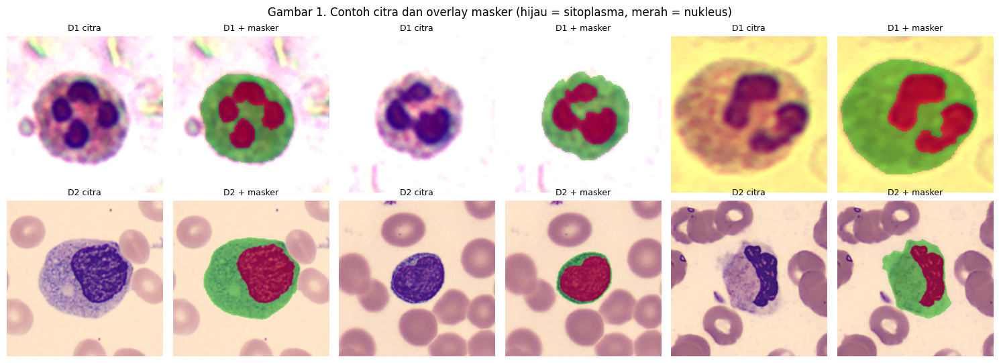

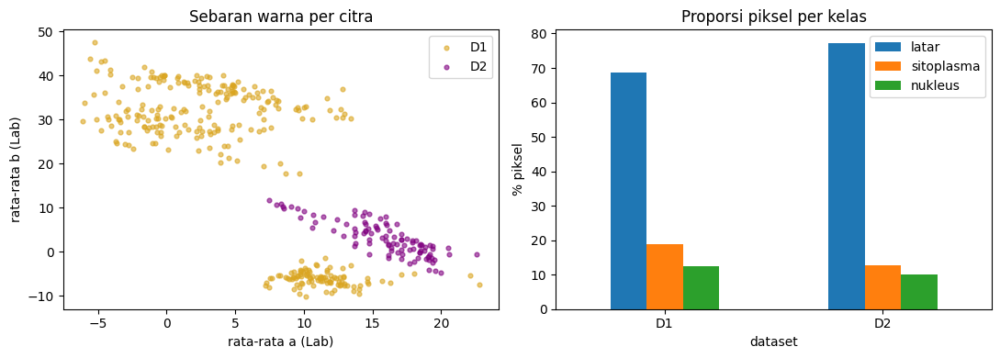

In [ ]:
def overlay(img, mask, alpha=0.45):
    out = img.astype(float).copy()
    for k, col in [(1, (0, 200, 0)), (2, (230, 0, 0))]:
        m = mask == k
        out[m] = (1 - alpha) * out[m] + alpha * np.array(col)
    return out.astype(np.uint8)

rng = np.random.RandomState(SEED)
fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
for r, dom in enumerate(DOMAINS):
    idx = rng.choice(len(DATA[dom]['img']), 3, replace=False)
    for j, i in enumerate(idx):
        ax[r, 2 * j].imshow(DATA[dom]['img'][i]); ax[r, 2 * j].set_title(f'{dom} citra', fontsize=9)
        ax[r, 2 * j + 1].imshow(overlay(DATA[dom]['img'][i], DATA[dom]['mask'][i])); ax[r, 2 * j + 1].set_title(f'{dom} + masker', fontsize=9)
for a in ax.ravel(): a.axis('off')
plt.suptitle('Gambar 1. Contoh citra dan overlay masker (hijau = sitoplasma, merah = nukleus)')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'gambar1_contoh_citra.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for dom, c in zip(DOMAINS, ['goldenrod', 'purple']):
    d = AUDIT[AUDIT.dataset == dom]
    ax[0].scatter(d.a_, d.b_, s=12, alpha=.6, c=c, label=dom)
ax[0].set_xlabel('rata-rata a (Lab)'); ax[0].set_ylabel('rata-rata b (Lab)'); ax[0].legend(); ax[0].set_title('Sebaran warna per citra')
prop = AUDIT.groupby('dataset')[['p_latar', 'p_sito', 'p_nuk']].mean()
prop.plot(kind='bar', ax=ax[1], rot=0); ax[1].set_ylabel('% piksel'); ax[1].set_title('Proporsi piksel per kelas')
ax[1].legend(['latar', 'sitoplasma', 'nukleus'])
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'eda_warna_dan_kelas.png', dpi=150); plt.show()

### Sel 11: Pemeriksaan duplikat dan kebocoran (SHA-256 + perceptual hash)
Dua cara menemukan citra kembar:
- **SHA-256**: sidik jari tepat. Sama = duplikat persis (piksel identik).
- **Perceptual hash (pHash, 64 bit)**: sidik jari "rupa". Jarak Hamming ≤ `PHASH_THRESH` = **sangat mirip** (misalnya citra yang sama tapi diberi sedikit perubahan).

Diperiksa di dalam D1, di dalam D2, dan **antar D1–D2**. Hasilnya dilaporkan walaupun nol. Daftar pasangan disimpan ke `logs/audit_duplikat.csv` dan ringkasannya ke `logs/audit_duplikat_ringkasan.json`.

In [ ]:
import imagehash

def phash_bits(arr):
    return np.array(imagehash.phash(Image.fromarray(arr), hash_size=8).hash, dtype=bool).ravel()

PH = {dom: np.stack([phash_bits(a) for a in DATA[dom]['img']]) for dom in DOMAINS}
SHA = {dom: AUDIT[AUDIT.dataset == dom].sha_pix.values for dom in DOMAINS}

def ham(A, B):
    return (A[:, None, :] != B[None, :, :]).sum(-1)

pair_rows = []
def collect(domA, domB):
    H = ham(PH[domA], PH[domB])
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            if domA == domB and j <= i:
                continue
            exact = SHA[domA][i] == SHA[domB][j]
            if exact or H[i, j] <= PHASH_THRESH:
                pair_rows.append(dict(set_A=domA, file_A=DATA[domA]['names'][i], idx_A=i, set_B=domB,
                                      file_B=DATA[domB]['names'][j], idx_B=j, hamming=int(H[i, j]),
                                      jenis='persis' if exact else 'sangat mirip'))
collect('D1', 'D1'); collect('D2', 'D2'); collect('D1', 'D2')
DUP = pd.DataFrame(pair_rows, columns=['set_A', 'file_A', 'idx_A', 'set_B', 'file_B', 'idx_B', 'hamming', 'jenis'])
DUP.to_csv(DIRS['logs'] / 'audit_duplikat.csv', index=False)

def cnt(a, b, jenis):
    return int(((DUP.set_A == a) & (DUP.set_B == b) & (DUP.jenis == jenis)).sum())
RINGKAS = {
    'ambang_phash': PHASH_THRESH, 'jenis_hash': 'phash 64 bit (imagehash)',
    'persis_D1': cnt('D1', 'D1', 'persis'), 'persis_D2': cnt('D2', 'D2', 'persis'), 'persis_D1_D2': cnt('D1', 'D2', 'persis'),
    'mirip_D1': cnt('D1', 'D1', 'sangat mirip'), 'mirip_D2': cnt('D2', 'D2', 'sangat mirip'), 'mirip_D1_D2': cnt('D1', 'D2', 'sangat mirip'),
}
json.dump(RINGKAS, open(DIRS['logs'] / 'audit_duplikat_ringkasan.json', 'w'), indent=2)
print(json.dumps(RINGKAS, indent=2))
if len(DUP): display(DUP.head(20))
else: print('\nTidak ada pasangan duplikat/sangat mirip pada ambang ini.')

# ukuran perbedaan terdekat (sebagai bukti tambahan walau tidak ada duplikat)
print('Jarak Hamming terkecil: D1-D1 =', int(np.min(ham(PH['D1'], PH['D1']) + 999 * np.eye(len(PH['D1']), dtype=int))),
      '| D2-D2 =', int(np.min(ham(PH['D2'], PH['D2']) + 999 * np.eye(len(PH['D2']), dtype=int))),
      '| D1-D2 =', int(ham(PH['D1'], PH['D2']).min()))

{
  "ambang_phash": 5,
  "jenis_hash": "phash 64 bit (imagehash)",
  "persis_D1": 1,
  "persis_D2": 0,
  "persis_D1_D2": 0,
  "mirip_D1": 3,
  "mirip_D2": 0,
  "mirip_D1_D2": 0
}


,set_A,file_A,idx_A,set_B,file_B,idx_B,hamming,jenis
0,D1,112.bmp,111,D1,139.bmp,138,0,persis
1,D1,157.bmp,156,D1,158.bmp,157,2,sangat mirip
2,D1,166.bmp,165,D1,171.bmp,170,4,sangat mirip
3,D1,167.bmp,166,D1,169.bmp,168,4,sangat mirip


Jarak Hamming terkecil: D1-D1 = 0 | D2-D2 = 12 | D1-D2 = 10


### Sel 12: Split tetap (seed 42, 70/10/20 per dataset) dan simpan CSV
- Pasangan citra duplikat/sangat mirip **di dalam satu dataset** digabung menjadi satu *grup* dan dimasukkan ke subset yang sama (mencegah kebocoran antar latih/validasi/uji). Bila tidak ada duplikat, tiap citra adalah grupnya sendiri.
- Hasil: D1 = 210/30/60, D2 = 70/10/20 (latih/validasi/uji), disimpan di `splits/split_seed42.csv`.
- Bila CSV sudah ada, notebook **memuat CSV itu** (bukan membuat ulang) sehingga split tetap sama di semua sesi.
- Bila ada pasangan duplikat **antar D1–D2**, sel ini memberi peringatan: citra tersebut harus ditangani manual (misalnya dikeluarkan dari set uji target) dan dicatat di laporan.

In [ ]:
def union_groups(n, pairs):
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for i, j in pairs:
        parent[find(i)] = find(j)
    return np.array([find(i) for i in range(n)])

def make_split(groups, ratios, seed):
    n = len(groups)
    t_tr, t_va = round(n * ratios[0]), round(n * ratios[1])
    targets = np.array([t_tr, t_va, n - t_tr - t_va])
    rng = np.random.RandomState(seed)
    ug = np.unique(groups); rng.shuffle(ug)
    subset = np.zeros(n, dtype=int); count = np.zeros(3, dtype=int)
    for g in ug:
        members = np.where(groups == g)[0]
        k = int(np.argmax(targets - count))      # subset yang paling kekurangan jatah
        subset[members] = k; count[k] += len(members)
    return subset

SPLIT_CSV = DIRS['splits'] / 'split_seed42.csv'
if SPLIT_CSV.exists():
    SPLIT_DF = pd.read_csv(SPLIT_CSV)
    print('Memuat split yang sudah tersimpan:', SPLIT_CSV)
else:
    parts = []
    for dom in DOMAINS:
        n = len(DATA[dom]['names'])
        pr = DUP[(DUP.set_A == dom) & (DUP.set_B == dom)][['idx_A', 'idx_B']].values.tolist()
        g = union_groups(n, pr)
        sub = make_split(g, SPLIT_RATIO, SEED)
        parts.append(pd.DataFrame(dict(dataset=dom, file=DATA[dom]['names'], idx=range(n), group=g,
                                       subset=np.array(['train', 'val', 'test'])[sub])))
    SPLIT_DF = pd.concat(parts, ignore_index=True)
    SPLIT_DF.to_csv(SPLIT_CSV, index=False)
    print('Split baru disimpan:', SPLIT_CSV)

SPLIT = {dom: {s: SPLIT_DF[(SPLIT_DF.dataset == dom) & (SPLIT_DF.subset == s)].idx.values for s in ['train', 'val', 'test']} for dom in DOMAINS}
for dom in DOMAINS:
    print(dom, {s: len(v) for s, v in SPLIT[dom].items()})

# pemeriksaan kebocoran antar subset (berdasar daftar duplikat)
leak = 0
sub_of = {(r.dataset, r.idx): r.subset for r in SPLIT_DF.itertuples()}
for r in DUP.itertuples():
    if r.set_A == r.set_B and sub_of[(r.set_A, r.idx_A)] != sub_of[(r.set_B, r.idx_B)]:
        leak += 1
print('Kebocoran antar subset latih/validasi/uji (pasangan duplikat di subset berbeda):', leak)
cross = DUP[DUP.set_A != DUP.set_B]
print('Pasangan duplikat antar domain D1-D2:', len(cross))
if len(cross):
    print('PERINGATAN: ada kemiripan antar domain. Tangani manual dan catat di laporan (Bagian 3.3).'); display(cross)

Split baru disimpan: /content/drive/MyDrive/TimTam_T3A/splits/split_seed42.csv
D1 {'train': 210, 'val': 30, 'test': 60}
D2 {'train': 70, 'val': 10, 'test': 20}
Kebocoran antar subset latih/validasi/uji (pasangan duplikat di subset berbeda): 0
Pasangan duplikat antar domain D1-D2: 0


### Sel 13: Pemeriksaan visual pra-pemrosesan (≥ 20 citra)
Menumpuk masker (hasil kuantisasi + resize 256×256) pada citra untuk **24 citra** dari semua subset dan kedua dataset. Lihat apakah masker pas dengan sel (tidak bergeser, tidak terbalik).

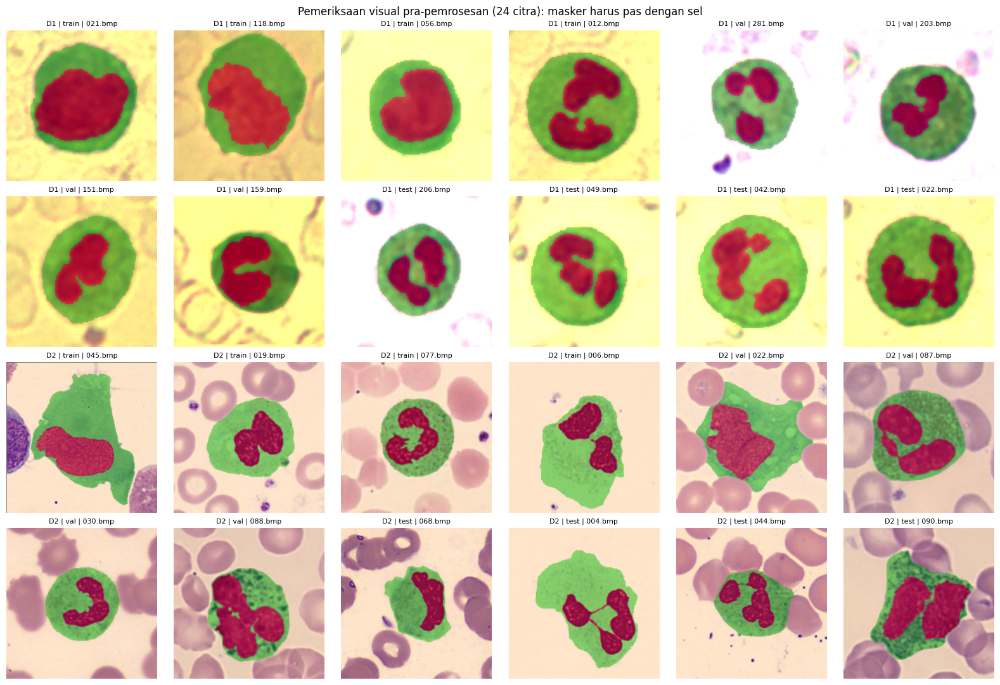

In [ ]:
rng = np.random.RandomState(0)
picks = []
for dom in DOMAINS:
    for s in ['train', 'val', 'test']:
        ids = rng.choice(SPLIT[dom][s], 4, replace=False)
        picks += [(dom, s, i) for i in ids]
fig, ax = plt.subplots(4, 6, figsize=(16, 11))
for a, (dom, s, i) in zip(ax.ravel(), picks):
    a.imshow(overlay(DATA[dom]['img'][i], DATA[dom]['mask'][i])); a.axis('off')
    a.set_title(f"{dom} | {s} | {DATA[dom]['names'][i]}", fontsize=8)
plt.suptitle('Pemeriksaan visual pra-pemrosesan (24 citra): masker harus pas dengan sel')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'cek_visual_praproses.png', dpi=130); plt.show()

## C. Alat bantu: normalisasi warna, jitter, model, metrik, pelatihan

### Sel 14: Normalisasi pewarnaan Reinhard dan Macenko
Dua metode menyeragamkan warna citra ke satu **referensi yang dihitung hanya dari set latih domain sumber** (M1 Bag. 2):
- **Reinhard**: di ruang Lab, rata-rata dan simpangan baku tiap kanal citra disamakan dengan referensi.
- **Macenko**: citra diurai menjadi dua komponen zat pewarna (lewat optical density dan SVD), lalu konsentrasinya disesuaikan dengan referensi. Metode ini dirancang untuk pewarnaan H&E, jadi pada apusan darah dipakai sebagai pendekatan. **Bila Macenko gagal pada suatu citra, otomatis dipakai Reinhard** dan kegagalannya dicatat (`logs/macenko_gagal_*.csv`, angkanya masuk Bagian 4.2 laporan).

Normalisasi diterapkan ke **semua citra** (latih, validasi, uji; D1 dan D2) memakai referensi dari set latih domain sumber, lalu hasilnya di-cache per pasangan (sumber, metode).

In [ ]:
IO, ALPHA, BETA = 240, 1, 0.15

def reinhard_fit(train_imgs):
    ms, ss = [], []
    for a in train_imgs:
        lab = skcolor.rgb2lab(a).reshape(-1, 3)
        ms.append(lab.mean(0)); ss.append(lab.std(0))
    return dict(mean=np.mean(ms, 0), std=np.mean(ss, 0))

def reinhard_apply(a, ref):
    lab = skcolor.rgb2lab(a)
    flat = lab.reshape(-1, 3)
    m, s = flat.mean(0), flat.std(0) + 1e-6
    lab2 = (lab - m) / s * ref['std'] + ref['mean']
    return (np.clip(skcolor.lab2rgb(lab2), 0, 1) * 255).round().astype(np.uint8)

def _od(a):
    return -np.log((a.reshape(-1, 3).astype(np.float64) + 1) / IO)

def _stain_matrix(OD):
    odhat = OD[~np.any(OD < BETA, axis=1)]
    if odhat.shape[0] < 200:
        raise ValueError('piksel berwarna terlalu sedikit')
    _, V = np.linalg.eigh(np.cov(odhat.T))
    V = V[:, [1, 2]].copy()
    if V[0, 0] < 0: V[:, 0] *= -1
    if V[0, 1] < 0: V[:, 1] *= -1
    that = odhat @ V
    phi = np.arctan2(that[:, 1], that[:, 0])
    lo, hi = np.percentile(phi, ALPHA), np.percentile(phi, 100 - ALPHA)
    v1 = V @ np.array([np.cos(lo), np.sin(lo)])
    v2 = V @ np.array([np.cos(hi), np.sin(hi)])
    HE = np.array([v1, v2]).T if v1[0] > v2[0] else np.array([v2, v1]).T
    if not np.all(np.isfinite(HE)):
        raise ValueError('matriks pewarna tidak valid')
    return HE

def _conc(HE, OD):
    C = np.linalg.lstsq(HE, OD.T, rcond=None)[0]
    return C, np.percentile(C, 99, axis=1)

def macenko_fit(train_imgs, n_pix=300000, seed=0):
    rng = np.random.RandomState(seed)
    per = n_pix // len(train_imgs) + 1
    ods = []
    for a in train_imgs:
        od = _od(a)
        ods.append(od[rng.choice(len(od), min(len(od), per), replace=False)])
    OD = np.concatenate(ods)
    HE = _stain_matrix(OD)
    _, maxC = _conc(HE, OD)
    return dict(HE=HE, maxC=maxC)

def macenko_apply(a, ref):
    OD = _od(a)
    HE = _stain_matrix(OD)
    C, maxC = _conc(HE, OD)
    if np.any(maxC < 1e-6) or not np.all(np.isfinite(maxC)):
        raise ValueError('konsentrasi tidak valid')
    C2 = C * (ref['maxC'] / maxC)[:, None]
    out = IO * np.exp(-ref['HE'] @ C2)
    out = np.clip(out, 0, 255).T.reshape(a.shape).round().astype(np.uint8)
    return out

class Normalizer:
    def __init__(self, method, train_imgs):
        self.method = method
        self.ref_r = reinhard_fit(train_imgs)
        self.ref_m = macenko_fit(train_imgs) if method == 'macenko' else None
        self.fail_count = 0
    def __call__(self, a):
        if self.method == 'reinhard':
            return reinhard_apply(a, self.ref_r), False
        try:
            return macenko_apply(a, self.ref_m), False
        except Exception:
            self.fail_count += 1
            return reinhard_apply(a, self.ref_r), True

NORMALIZERS, NORM_CACHE = {}, {}
def get_normalizer(source, method):
    key = (source, method)
    if key not in NORMALIZERS:
        NORMALIZERS[key] = Normalizer(method, DATA[source]['img'][SPLIT[source]['train']])
    return NORMALIZERS[key]

def get_norm_arrays(source, method):
    key = (source, method)
    if key in NORM_CACHE:
        return NORM_CACHE[key]
    nz = get_normalizer(source, method)
    out, fails = {}, []
    for dom in DOMAINS:
        arr = []
        for i, a in enumerate(tqdm(DATA[dom]['img'], desc=f'{method} ref={source} -> {dom}', leave=False)):
            b, failed = nz(a)
            arr.append(b)
            if failed: fails.append(dict(sumber=source, metode=method, dataset=dom, file=DATA[dom]['names'][i]))
        out[dom] = np.stack(arr)
    NORM_CACHE[key] = out
    pd.DataFrame(fails, columns=['sumber', 'metode', 'dataset', 'file']).to_csv(DIRS['logs'] / f'normalisasi_gagal_{method}_ref{source}.csv', index=False)
    print(f'{method} (referensi {source}): {len(fails)} citra gagal -> fallback Reinhard' if method == 'macenko' else f'{method} (referensi {source}) selesai')
    return out

def get_arrays(source, cond):
    return get_norm_arrays(source, cond) if cond in ('reinhard', 'macenko') else {d: DATA[d]['img'] for d in DOMAINS}

### Sel 15: Lihat hasil normalisasi (pemeriksaan visual)
Menampilkan satu citra D2 (keunguan) sebelum dan sesudah Reinhard/Macenko dengan referensi D1 (kekuningan), dan sebaliknya. Tujuannya memastikan hasilnya masuk akal (sel tidak rusak, warna mendekati domain sumber).

NB: Macenko dirancang untuk pewarnaan H&E dan membangun ulang citra dari dua komponen pewarna, sehingga latar bisa tampak lebih putih/pucat dan warnanya tidak persis seperti domain sumber. Reinhard menggeser warna seluruh citra (termasuk latar) sehingga lebih dekat ke domain sumber.

reinhard ref=D1 -> D1:   0%|          | 0/300 [00:00<?, ?it/s]

reinhard ref=D1 -> D2:   0%|          | 0/100 [00:00<?, ?it/s]

reinhard (referensi D1) selesai


macenko ref=D1 -> D1:   0%|          | 0/300 [00:00<?, ?it/s]

macenko ref=D1 -> D2:   0%|          | 0/100 [00:00<?, ?it/s]

macenko (referensi D1): 0 citra gagal -> fallback Reinhard


... (2 outputs left out)

reinhard (referensi D2) selesai


macenko ref=D2 -> D1:   0%|          | 0/300 [00:00<?, ?it/s]

macenko ref=D2 -> D2:   0%|          | 0/100 [00:00<?, ?it/s]

macenko (referensi D2): 0 citra gagal -> fallback Reinhard


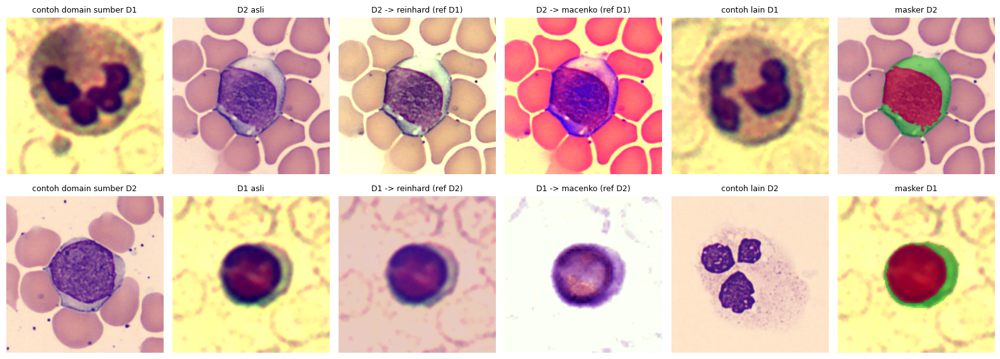

In [ ]:
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for r, (src, tgt) in enumerate([('D1', 'D2'), ('D2', 'D1')]):
    i = SPLIT[tgt]['test'][0]
    ax[r, 0].imshow(DATA[src]['img'][SPLIT[src]['train'][0]]); ax[r, 0].set_title(f'contoh domain sumber {src}', fontsize=9)
    ax[r, 1].imshow(DATA[tgt]['img'][i]); ax[r, 1].set_title(f'{tgt} asli', fontsize=9)
    for k, mth in enumerate(['reinhard', 'macenko']):
        ax[r, 2 + k].imshow(get_norm_arrays(src, mth)[tgt][i]); ax[r, 2 + k].set_title(f'{tgt} -> {mth} (ref {src})', fontsize=9)
    ax[r, 4].imshow(DATA[src]['img'][SPLIT[src]['train'][1]]); ax[r, 4].set_title(f'contoh lain {src}', fontsize=9)
    ax[r, 5].imshow(overlay(DATA[tgt]['img'][i], DATA[tgt]['mask'][i])); ax[r, 5].set_title(f'masker {tgt}', fontsize=9)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'contoh_normalisasi.png', dpi=130); plt.show()

### Sel 16: Color jitter (HSV), augmentasi geometrik, dan penyiapan batch
- **Geometrik** (semua kondisi): flip horizontal, flip vertikal, rotasi 90° acak. Diterapkan sama persis pada citra dan masker.
- **Color jitter** (hanya kondisi jitter, hanya saat pelatihan): kecerahan, kontras, saturasi, dan hue acak sesuai level di `JITTER`. Hanya mengubah citra, **tidak** masker.
- **Penskalaan ImageNet** (rerata/simpangan baku ImageNet) selalu dipakai karena encoder dilatih-awal di ImageNet. Ini *bukan* normalisasi pewarnaan, jadi baseline tetap "tanpa normalisasi pewarnaan".

Seluruh data kecil dimuat ke GPU sekaligus agar pelatihan cepat.

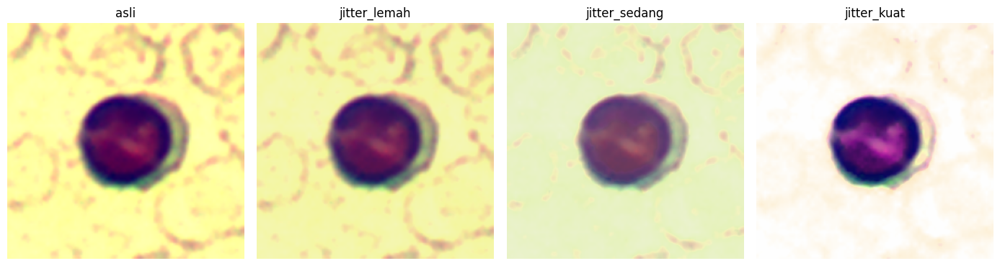

In [ ]:
from torchvision.transforms import ColorJitter
IM_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_gpu_u8(arr):                 # N,H,W,3 uint8 -> N,3,H,W uint8 di GPU
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous().to(device)

def imagenet_scale(x01):            # x01: float 0..1
    return (x01 - IM_MEAN.to(x01.device)) / IM_STD.to(x01.device)

def make_jitter(spec):
    return None if spec is None else ColorJitter(brightness=spec['b'], contrast=spec['c'], saturation=spec['s'], hue=spec['h'])

def augment_batch(x, y, jit):
    xs, ys = [], []
    for i in range(x.shape[0]):
        xi, yi = x[i], y[i]
        if random.random() < 0.5: xi, yi = xi.flip(-1), yi.flip(-1)
        if random.random() < 0.5: xi, yi = xi.flip(-2), yi.flip(-2)
        k = random.randint(0, 3)
        if k: xi, yi = torch.rot90(xi, k, (-2, -1)), torch.rot90(yi, k, (-2, -1))
        if jit is not None: xi = jit(xi)
        xs.append(xi); ys.append(yi)
    return torch.stack(xs), torch.stack(ys)

# pratinjau jitter: satu citra D1 pada tiga level
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
x0 = to_gpu_u8(DATA['D1']['img'][:1]).float() / 255
ax[0].imshow(DATA['D1']['img'][0]); ax[0].set_title('asli')
for a, (nm, sp) in zip(ax[1:], JITTER.items()):
    a.imshow(make_jitter(sp)(x0[0]).permute(1, 2, 0).cpu().numpy()); a.set_title(nm)
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'contoh_jitter.png', dpi=130); plt.show()

### Sel 17: Metrik evaluasi
Per citra dan per kelas (nukleus, sitoplasma):
- **Dice** dan **IoU**; **mIoU** = rerata IoU kedua kelas (latar tidak dihitung).
- **HD95**: persentil ke-95 jarak Hausdorff (piksel, pada 256×256) antara tepi prediksi dan tepi masker asli.
- **Penanganan masker kosong** (tulis di Bagian 4.5 laporan): bila prediksi **dan** masker asli sama-sama kosong untuk suatu kelas, Dice = IoU = 1 dan HD95 = 0; bila **hanya satu** yang kosong, Dice = IoU = 0 dan HD95 diberi nilai penalti maksimum, yaitu panjang diagonal citra (≈ 362 piksel).

Juga dicatat luas dan jumlah komponen per kelas, dipakai nanti untuk hasil menurut ukuran sel dan kategori kesalahan.

In [ ]:
from scipy.ndimage import distance_transform_edt, binary_erosion
HD_MAX = float(np.sqrt(2) * IMG)

def dice_iou(p, g):
    if not p.any() and not g.any(): return 1.0, 1.0
    inter = (p & g).sum(); union = (p | g).sum()
    return 2 * inter / (p.sum() + g.sum()), inter / union

def hd95(p, g):
    if not p.any() and not g.any(): return 0.0
    if not p.any() or not g.any(): return HD_MAX
    bp = p & ~binary_erosion(p); bg = g & ~binary_erosion(g)
    if not bp.any(): bp = p
    if not bg.any(): bg = g
    d_to_g = distance_transform_edt(~bg); d_to_p = distance_transform_edt(~bp)
    return float(np.percentile(np.concatenate([d_to_g[bp], d_to_p[bg]]), 95))

def metrics_df(pred, gt, names):
    rows = []
    for k in range(len(pred)):
        r = dict(file=names[k])
        for cls, nm in [(2, 'nuk'), (1, 'sito')]:
            p, g = pred[k] == cls, gt[k] == cls
            d, i = dice_iou(p, g)
            r[f'dice_{nm}'], r[f'iou_{nm}'], r[f'hd95_{nm}'] = d, i, hd95(p, g)
            r[f'area_{nm}_gt'], r[f'area_{nm}_pred'] = int(g.sum()), int(p.sum())
            r[f'ncomp_{nm}_gt'], r[f'ncomp_{nm}_pred'] = int(ndi.label(g)[1]), int(ndi.label(p)[1])
        r['miou'] = (r['iou_nuk'] + r['iou_sito']) / 2
        rows.append(r)
    return pd.DataFrame(rows)

# uji cepat metrik pada data buatan
_g = np.zeros((IMG, IMG), np.uint8); _g[100:150, 100:150] = 2
print('uji metrik (harus Dice=1, HD95=0):', dice_iou(_g == 2, _g == 2), hd95(_g == 2, _g == 2))
print('uji metrik prediksi kosong (Dice=0, HD95=penalti):', dice_iou(np.zeros_like(_g, bool), _g == 2), hd95(np.zeros_like(_g, bool), _g == 2))

uji metrik (harus Dice=1, HD95=0): (np.float64(1.0), np.float64(1.0)) 0.0
uji metrik prediksi kosong (Dice=0, HD95=penalti): (np.float64(0.0), np.float64(0.0)) 362.03867196751236


### Sel 18: Model, loss, prediksi, dan fungsi latih
- **Model**: `build_model('unet')` = U-Net ResNet-34, `build_model('deeplab')` = DeepLabV3+ ResNet-34, keduanya berbobot ImageNet, 3 kelas keluaran.
- **Loss**: CrossEntropy + Dice (multikelas).
- **Pelatihan**: fine-tuning **penuh**, Adam lr 1e-4, batch 16, mixed precision (AMP) agar cepat di T4, maksimum `MAX_EPOCHS` epoch.
- **Early stopping**: berhenti bila Dice validasi domain sumber (rerata Dice nukleus dan sitoplasma) tidak membaik selama `PATIENCE` epoch; bobot terbaik dipulihkan.
- Hasil: model terbaik, riwayat per epoch, epoch terbaik, waktu latih.

In [ ]:
def build_model(arch, pretrained=True):
    w = 'imagenet' if pretrained else None
    if arch == 'unet':
        return smp.Unet('resnet34', encoder_weights=w, in_channels=3, classes=3)
    if arch == 'deeplab':
        return smp.DeepLabV3Plus('resnet34', encoder_weights=w, in_channels=3, classes=3)
    raise ValueError(arch)

def n_params_million(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

dice_loss_fn = smp.losses.DiceLoss(mode='multiclass')
ce_loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def predict_u8(model, imgs, bs=32):
    model.eval(); out = []
    for i in range(0, len(imgs), bs):
        x = imagenet_scale(to_gpu_u8(imgs[i:i + bs]).float() / 255)
        with torch.autocast('cuda', enabled=USE_AMP):
            lg = model(x)
        out.append(lg.argmax(1).byte().cpu())
    return torch.cat(out).numpy()

def quick_val_dice(pred, gt):
    vals = []
    for k in range(len(pred)):
        vals.append(np.mean([dice_iou(pred[k] == c, gt[k] == c)[0] for c in (1, 2)]))
    return float(np.mean(vals))

def train_model(arch, Xtr, Ytr, Xva, Yva, jit_spec, seed, verbose=True):
    set_seed(seed)
    model = build_model(arch).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    jit = make_jitter(jit_spec)
    xg, yg = to_gpu_u8(Xtr), torch.from_numpy(Ytr).long().to(device)
    n = len(xg); hist = []
    best, best_ep, bad, best_state = -1.0, 0, 0, None
    t0 = time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); perm = torch.randperm(n, device=device); tl = 0.0; nb = 0
        for s in range(0, n, BATCH):
            idx = perm[s:s + BATCH]
            if len(idx) < 2: continue
            xb, yb = augment_batch(xg[idx].float() / 255, yg[idx], jit)
            xb = imagenet_scale(xb)
            with torch.autocast('cuda', enabled=USE_AMP):
                lg = model(xb)
                loss = ce_loss_fn(lg, yb) + dice_loss_fn(lg, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item(); nb += 1
        vd = quick_val_dice(predict_u8(model, Xva), Yva)
        hist.append(dict(epoch=ep, train_loss=tl / max(nb, 1), val_dice=vd))
        if vd > best:
            best, best_ep, bad = vd, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if verbose and (ep % 10 == 0 or ep == 1):
            print(f'  epoch {ep:3d} | loss {tl / max(nb, 1):.4f} | Dice val {vd:.4f} | terbaik {best:.4f} (ep {best_ep})')
        if bad >= PATIENCE:
            break
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), dict(best_epoch=best_ep, best_val_dice=best, epochs_run=len(hist), train_time_sec=train_time)

### Sel 19: Efisiensi (parameter dan latensi)
Dua fungsi: jumlah parameter (juta) dan **latensi batch 1** setelah *warm-up*, dirata-rata pada ≥ 50 citra nyata, **tanpa AMP (float32)**, pada satu GPU yang sama.

In [ ]:
def measure_latency(model, n=60, warmup=10):
    model.eval()
    pool = DATA['D1']['img'][SPLIT['D1']['test']]
    xs = [imagenet_scale(to_gpu_u8(pool[i % len(pool)][None]).float() / 255) for i in range(n)]
    ts = []
    with torch.no_grad():
        for i in range(warmup):
            model(xs[i % len(xs)])
        if device == 'cuda': torch.cuda.synchronize()
        for x in xs:
            t = time.perf_counter(); model(x)
            if device == 'cuda': torch.cuda.synchronize()
            ts.append((time.perf_counter() - t) * 1000)
    return float(np.mean(ts)), float(np.std(ts))

### Sel 20: Pelaksana run
`run_experiment(arch, sumber, target, kondisi, seed)` melakukan satu run lengkap:
1. siapkan data sesuai **kondisi**: `baseline`, `reinhard`, `macenko`, `jitter_lemah`, `jitter_sedang`, `jitter_kuat`;
2. latih di domain sumber (latih) dengan validasi di domain sumber;
3. evaluasi pada: **uji sumber** (`in`), **uji target** (`cross`, dipakai satu kali), serta **validasi target** (`val_target`, hanya untuk memilih konfigurasi) dan validasi sumber;
4. simpan per-citra (`results/<run_id>/per_image.csv`), ringkasan (`summary.json`), riwayat latih (`history.csv`), dan bobot fp16 (`ckpt/<run_id>.pt`).

run yang sudah punya `summary.json` dilewati. Run yang gagal dicatat di `logs/run_gagal.csv` dan tidak menghentikan notebook.

Nama run: `<arsitektur>_<sumber>to<target>_<kondisi>_s<seed>`, contoh `unet_D1toD2_baseline_s42`.

In [ ]:
def run_id_of(arch, source, target, cond, seed):
    return f'{arch}_{source}to{target}_{cond}_s{seed}'

def run_experiment(arch, source, target, cond, seed, verbose=True):
    rid = run_id_of(arch, source, target, cond, seed)
    rdir = DIRS['results'] / rid
    if (rdir / 'summary.json').exists():
        return json.load(open(rdir / 'summary.json'))
    rdir.mkdir(parents=True, exist_ok=True)
    print(f'>>> {rid}')
    try:
        A = get_arrays(source, cond)
        tr, va = SPLIT[source]['train'], SPLIT[source]['val']
        model, hist, info = train_model(arch, A[source][tr], DATA[source]['mask'][tr], A[source][va], DATA[source]['mask'][va],
                                        JITTER.get(cond), seed, verbose)
        evals = {'in': (source, 'test'), 'cross': (target, 'test'), 'val_target': (target, 'val'), 'val_source': (source, 'val')}
        frames = []
        for k, (dom, sub) in evals.items():
            idx = SPLIT[dom][sub]
            pred = predict_u8(model, A[dom][idx])
            df = metrics_df(pred, DATA[dom]['mask'][idx], [DATA[dom]['names'][i] for i in idx])
            df['eval_set'] = k; df['idx'] = idx
            frames.append(df)
        per = pd.concat(frames, ignore_index=True)
        per.to_csv(rdir / 'per_image.csv', index=False)
        hist.to_csv(rdir / 'history.csv', index=False)
        torch.save({k: (v.half() if v.is_floating_point() else v) for k, v in model.state_dict().items()}, DIRS['ckpt'] / f'{rid}.pt')
        g = lambda es, m: float(per[per.eval_set == es][m].mean())
        summ = dict(run_id=rid, arch=arch, source=source, target=target, cond=cond, seed=seed, **info,
                    n_params_m=n_params_million(model), gpu=GPU_NAME,
                    in_dice_sito=g('in', 'dice_sito'), in_dice_nuk=g('in', 'dice_nuk'), in_miou=g('in', 'miou'),
                    cross_dice_sito=g('cross', 'dice_sito'), cross_dice_nuk=g('cross', 'dice_nuk'), cross_miou=g('cross', 'miou'),
                    val_target_dice_sito=g('val_target', 'dice_sito'))
        json.dump(summ, open(rdir / 'summary.json', 'w'), indent=2)
        print(f'    selesai: Dice sito in {summ["in_dice_sito"]:.4f} | cross {summ["cross_dice_sito"]:.4f} | {info["train_time_sec"] / 60:.1f} menit')
        del model; torch.cuda.empty_cache()
        return summ
    except Exception as e:
        print('    GAGAL:', repr(e))
        with open(DIRS['logs'] / 'run_gagal.csv', 'a') as f:
            f.write(f'{rid},{repr(e)[:200].replace(",", ";")}\n')
        return None

def load_summaries():
    rows = [json.load(open(p)) for p in sorted(DIRS['results'].glob('*/summary.json'))]
    return pd.DataFrame(rows)

def per_image(rid, eval_set):
    df = pd.read_csv(DIRS['results'] / rid / 'per_image.csv')
    return df[df.eval_set == eval_set].reset_index(drop=True)

def load_run_model(rid):
    s = json.load(open(DIRS['results'] / rid / 'summary.json'))
    m = build_model(s['arch'], pretrained=False)
    m.load_state_dict(torch.load(DIRS['ckpt'] / f'{rid}.pt', map_location='cpu'))
    return m.to(device).eval(), s

def save_table(df, name, index=True):
    df.to_csv(DIRS['tables'] / f'{name}.csv', index=index)

## D. Baseline M2: U-Net ResNet-34, latih D1, uji D1 dan D2

### Sel 21: Latih dan evaluasi baseline
Satu run: U-Net, ImageNet pralatih, fine-tuning penuh, CE+Dice, 256×256, Adam lr 1e-4, batch 16, augmentasi geometrik saja (tanpa normalisasi pewarnaan, tanpa jitter), seed 42. Dilatih di D1, diuji di uji D1 (in-domain, n=60) dan uji D2 (cross-domain, n=20).

Run ini sekaligus menjadi *baseline* pada Ablasi 1 dan Uji utama (tidak dilatih ulang).

In [ ]:
base = run_experiment('unet', 'D1', 'D2', 'baseline', 42)
base

>>> unet_D1toD2_baseline_s42


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  epoch   1 | loss 1.5331 | Dice val 0.4047 | terbaik 0.4047 (ep 1)
  epoch  10 | loss 0.3717 | Dice val 0.9209 | terbaik 0.9209 (ep 10)
  epoch  20 | loss 0.1756 | Dice val 0.9316 | terbaik 0.9414 (ep 19)
  epoch  30 | loss 0.1342 | Dice val 0.9438 | terbaik 0.9439 (ep 26)
  epoch  40 | loss 0.0962 | Dice val 0.9438 | terbaik 0.9520 (ep 36)
  epoch  50 | loss 0.0944 | Dice val 0.9441 | terbaik 0.9520 (ep 36)
    selesai: Dice sito in 0.9506 | cross 0.5429 | 1.5 menit


{'run_id': 'unet_D1toD2_baseline_s42',
 'arch': 'unet',
 'source': 'D1',
 'target': 'D2',
 'cond': 'baseline',
 'seed': 42,
 'best_epoch': 36,
 'best_val_dice': 0.9519629146737062,
 'epochs_run': 51,
 'train_time_sec': 92.52168154716492,
 'n_params_m': 24.436659,
 'gpu': 'Tesla T4',
 'in_dice_sito': 0.95055373865584,
 'in_dice_nuk': 0.9635886173973733,
 'in_miou': 0.9187078912005777,
 'cross_dice_sito': 0.5429417574847449,
 'cross_dice_nuk': 0.7887047573773481,
 'cross_miou': 0.5708898132011783,
 'val_target_dice_sito': 0.4003408812281973}

### Sel 22: Tabel baseline M2 (Bagian 4 laporan M2)
Angka dalam **persen** untuk Dice dan IoU, rerata ± SD **per citra** pada set uji; HD95 dalam piksel. Baris terakhir = selisih in-domain − cross-domain. Di bawahnya: epoch berhenti, Dice validasi terbaik, waktu latih, parameter, dan latensi batch 1.

In [ ]:
def ms(s, scale=1.0, nd=2):
    return f'{s.mean() * scale:.{nd}f} ± {s.std() * scale:.{nd}f}'

rid0 = 'unet_D1toD2_baseline_s42'
pin, pcr = per_image(rid0, 'in'), per_image(rid0, 'cross')
cols = [('Dice nuk.', 'dice_nuk', 100), ('Dice sito.', 'dice_sito', 100), ('IoU nuk.', 'iou_nuk', 100), ('IoU sito.', 'iou_sito', 100),
        ('mIoU', 'miou', 100), ('HD95 nuk.', 'hd95_nuk', 1), ('HD95 sito.', 'hd95_sito', 1)]
T_M2 = pd.DataFrame({
    f'In-domain (D1 uji, n={len(pin)})': {n: ms(pin[c], s) for n, c, s in cols},
    f'Cross-domain (D2 uji, n={len(pcr)})': {n: ms(pcr[c], s) for n, c, s in cols},
    'Selisih (in - cross)': {n: f'{(pin[c].mean() - pcr[c].mean()) * s:+.2f}' for n, c, s in cols},
}).T
display(T_M2); save_table(T_M2, 'tabel_m2_baseline')

mdl, _ = load_run_model(rid0)
lat_m, lat_s = measure_latency(mdl)
print(f"Berhenti di epoch {base['best_epoch']} (dari {base['epochs_run']} epoch dijalankan) | Dice validasi terbaik {base['best_val_dice'] * 100:.2f}")
print(f"Waktu latih {base['train_time_sec'] / 60:.1f} menit | GPU {base['gpu']}")
print(f"Parameter {base['n_params_m']:.2f} juta | latensi batch 1 {lat_m:.1f} ± {lat_s:.1f} ms/citra")
del mdl

,Dice nuk.,Dice sito.,IoU nuk.,IoU sito.,mIoU,HD95 nuk.,HD95 sito.
"In-domain (D1 uji, n=60)",96.36 ± 2.33,95.06 ± 2.49,93.06 ± 4.05,90.68 ± 4.37,91.87 ± 3.33,4.35 ± 9.36,3.59 ± 4.37
"Cross-domain (D2 uji, n=20)",78.87 ± 28.13,54.29 ± 30.24,71.40 ± 28.99,42.78 ± 28.45,57.09 ± 25.78,31.71 ± 78.63,43.19 ± 45.99
Selisih (in - cross),+17.49,+40.76,+21.67,+47.90,+34.78,-27.36,-39.60


Berhenti di epoch 36 (dari 51 epoch dijalankan) | Dice validasi terbaik 95.20
Waktu latih 1.5 menit | GPU Tesla T4
Parameter 24.44 juta | latensi batch 1 7.9 ± 1.9 ms/citra


**Arti awal (untuk M2):** lihat baris "Selisih". Selisih positif berarti Dice turun saat pindah ke domain D2.

---
## E. Ablasi 1 dan Ablasi 2 (U-Net, seed 42, kedua arah)

### Sel 23: Jalankan ablasi
- **Ablasi 1 (Elfina):** tanpa normalisasi (baseline) vs Reinhard vs Macenko.
- **Ablasi 2 (Nayzila):** jitter lemah vs sedang vs kuat.

Masing-masing di dua arah (D1→D2 dan D2→D1). Baseline U-Net seed 42 D1→D2 sudah selesai di Sel 21, sehingga tidak diulang. Estimasi: 12 run, sebagian besar ±2–3 menit.

In [ ]:
DIRS_PAIR = [('D1', 'D2'), ('D2', 'D1')]
ABL_NORM = ['reinhard', 'macenko']
ABL_JIT = ['jitter_lemah', 'jitter_sedang', 'jitter_kuat']
for src, tgt in DIRS_PAIR:
    for cond in ['baseline'] + ABL_NORM + ABL_JIT:
        run_experiment('unet', src, tgt, cond, 42)
print('\nAblasi selesai.')

>>> unet_D1toD2_reinhard_s42
  epoch   1 | loss 1.5321 | Dice val 0.4784 | terbaik 0.4784 (ep 1)
  epoch  10 | loss 0.3743 | Dice val 0.9123 | terbaik 0.9175 (ep 7)
  epoch  20 | loss 0.1776 | Dice val 0.9379 | terbaik 0.9379 (ep 20)
  epoch  30 | loss 0.1362 | Dice val 0.9342 | terbaik 0.9379 (ep 20)
  epoch  40 | loss 0.0978 | Dice val 0.9405 | terbaik 0.9405 (ep 40)
  epoch  50 | loss 0.0931 | Dice val 0.9382 | terbaik 0.9416 (ep 48)
  epoch  60 | loss 0.0848 | Dice val 0.9358 | terbaik 0.9455 (ep 57)
  epoch  70 | loss 0.0699 | Dice val 0.9376 | terbaik 0.9455 (ep 57)
    selesai: Dice sito in 0.9506 | cross 0.2790 | 2.3 menit
>>> unet_D1toD2_macenko_s42
  epoch   1 | loss 1.5616 | Dice val 0.3664 | terbaik 0.3664 (ep 1)
  epoch  10 | loss 0.4032 | Dice val 0.8857 | terbaik 0.8857 (ep 10)
  epoch  20 | loss 0.1936 | Dice val 0.9166 | terbaik 0.9228 (ep 19)
  epoch  30 | loss 0.1469 | Dice val 0.9305 | terbaik 0.9305 (ep 30)
  epoch  40 | loss 0.1129 | Dice val 0.9275 | terbaik 0.93

### Sel 24: Tabel 3 laporan dan pemilihan konfigurasi terbaik
- **Tabel 3:** Dice sitoplasma (%) seed 42, in-domain dan cross-domain, tiap kondisi dan arah.
- **Aturan pemilihan (M1):** normalisasi terbaik dan level jitter terbaik dipilih dari **Dice sitoplasma pada set validasi domain target** (dirata-rata dua arah). **Set uji tidak dipakai untuk memilih.** Pemakaian label validasi target ini adalah keterbatasan yang sudah ditulis di laporan.

In [ ]:
S = load_summaries()
def sv(cond, src, tgt, key, arch='unet', seed=42):
    r = S[(S.arch == arch) & (S.cond == cond) & (S.source == src) & (S.target == tgt) & (S.seed == seed)]
    return float(r[key].iloc[0]) if len(r) else np.nan

def val_score(cond):   # rata-rata Dice sito validasi target di dua arah
    return np.nanmean([sv(cond, s, t, 'val_target_dice_sito') for s, t in DIRS_PAIR])

SCORES = {c: val_score(c) for c in ABL_NORM + ABL_JIT}
BEST_NORM = max(ABL_NORM, key=lambda c: SCORES[c])
BEST_JIT = max(ABL_JIT, key=lambda c: SCORES[c])
print('Dice sito validasi target (rerata 2 arah, %):', {k: round(v * 100, 2) for k, v in SCORES.items()})
print(f'==> Normalisasi terpilih: {BEST_NORM} | Jitter terpilih: {BEST_JIT}')
json.dump(dict(best_norm=BEST_NORM, best_jit=BEST_JIT, val_scores=SCORES), open(DIRS['logs'] / 'konfigurasi_terpilih.json', 'w'), indent=2)

labels = {'baseline': 'Tanpa normalisasi (baseline)', 'reinhard': 'Reinhard', 'macenko': 'Macenko',
          'jitter_lemah': 'Jitter lemah', 'jitter_sedang': 'Jitter sedang', 'jitter_kuat': 'Jitter kuat'}
rows = []
for c in ['baseline'] + ABL_NORM + ABL_JIT:
    mark = ' (*)' if c in (BEST_NORM, BEST_JIT) else ''
    rows.append({'Kondisi': labels[c] + mark,
                 'D1→D2 in-domain': sv(c, 'D1', 'D2', 'in_dice_sito') * 100, 'D1→D2 cross': sv(c, 'D1', 'D2', 'cross_dice_sito') * 100,
                 'D2→D1 in-domain': sv(c, 'D2', 'D1', 'in_dice_sito') * 100, 'D2→D1 cross': sv(c, 'D2', 'D1', 'cross_dice_sito') * 100,
                 'Dice val. target (dasar pemilihan)': (SCORES.get(c, np.nan)) * 100})
TABEL3 = pd.DataFrame(rows).set_index('Kondisi').round(2)
display(TABEL3); save_table(TABEL3, 'tabel3_ablasi')

Dice sito validasi target (rerata 2 arah, %): {'reinhard': np.float64(37.89), 'macenko': np.float64(57.16), 'jitter_lemah': np.float64(49.32), 'jitter_sedang': np.float64(59.99), 'jitter_kuat': np.float64(73.66)}
==> Normalisasi terpilih: macenko | Jitter terpilih: jitter_kuat


,D1→D2 in-domain,D1→D2 cross,D2→D1 in-domain,D2→D1 cross,Dice val. target (dasar pemilihan)
Kondisi,,,,,
Tanpa normalisasi (baseline),95.06,54.29,94.51,36.62,NaN
Reinhard,95.06,27.90,93.07,56.79,37.89
Macenko (*),93.81,68.50,91.42,56.19,57.16
Jitter lemah,94.61,54.58,94.44,44.55,49.32
Jitter sedang,95.11,56.58,93.87,63.57,59.99
Jitter kuat (*),94.61,73.66,93.18,74.61,73.66


---
## F. Uji utama (3 seed)

### Sel 25: Jalankan uji utama
Membandingkan **baseline**, **normalisasi terbaik**, dan **jitter terbaik** pada **U-Net dan DeepLabV3+**, kedua arah, **seed 42, 43, 44** = 2 × 2 × 3 × 3 = **36 run**. Run seed 42 U-Net yang sudah ada dari ablasi dipakai ulang otomatis.

In [ ]:
MAIN_CONDS = ['baseline', BEST_NORM, BEST_JIT]
for arch in ARCHS:
    for src, tgt in DIRS_PAIR:
        for cond in MAIN_CONDS:
            for seed in SEEDS_MAIN:
                run_experiment(arch, src, tgt, cond, seed)
S = load_summaries()
print('\nTotal run selesai:', len(S), '| total run uji utama diharapkan: 36 (+ ablasi lain)')

>>> unet_D1toD2_baseline_s43
  epoch   1 | loss 1.3384 | Dice val 0.4774 | terbaik 0.4774 (ep 1)
  epoch  10 | loss 0.2535 | Dice val 0.9206 | terbaik 0.9206 (ep 10)
  epoch  20 | loss 0.1351 | Dice val 0.9347 | terbaik 0.9353 (ep 19)
  epoch  30 | loss 0.1154 | Dice val 0.9374 | terbaik 0.9386 (ep 26)
  epoch  40 | loss 0.0902 | Dice val 0.9412 | terbaik 0.9418 (ep 34)
  epoch  50 | loss 0.0890 | Dice val 0.9388 | terbaik 0.9424 (ep 43)
    selesai: Dice sito in 0.9478 | cross 0.7015 | 1.8 menit
>>> unet_D1toD2_baseline_s44
  epoch   1 | loss 1.9370 | Dice val 0.2962 | terbaik 0.2962 (ep 1)
  epoch  10 | loss 0.4342 | Dice val 0.9097 | terbaik 0.9117 (ep 9)
  epoch  20 | loss 0.2454 | Dice val 0.9059 | terbaik 0.9276 (ep 16)
  epoch  30 | loss 0.1619 | Dice val 0.9360 | terbaik 0.9367 (ep 29)
  epoch  40 | loss 0.1355 | Dice val 0.9331 | terbaik 0.9427 (ep 35)
  epoch  50 | loss 0.1133 | Dice val 0.9459 | terbaik 0.9467 (ep 47)
  epoch  60 | loss 0.0938 | Dice val 0.9494 | terbaik 0.9

### Sel 26: Tabel 4 laporan (rerata ± SD antar seed)
Setiap seed menghasilkan **satu nilai** (rerata per citra pada set uji), lalu dirata-rata dan dihitung SD **antar tiga seed** (SD sampel, n−1). Dice/mIoU dalam %, HD95 dalam piksel, **Selisih = Dice sito. in-domain − cross-domain** (poin; makin kecil makin baik, artinya makin tahan pergeseran domain).

Tabel lengkap (termasuk in-domain dan IoU per kelas) disimpan sebagai lampiran: `tables/lampiran_uji_utama_semua_metrik.csv`.

In [ ]:
MET = ['dice_nuk', 'dice_sito', 'iou_nuk', 'iou_sito', 'miou', 'hd95_nuk', 'hd95_sito']
def run_metrics(rid):
    pi = pd.read_csv(DIRS['results'] / rid / 'per_image.csv')
    out = {}
    for es in ['in', 'cross']:
        d = pi[pi.eval_set == es]
        for m in MET: out[f'{es}_{m}'] = d[m].mean()
    out['gap_dice_sito'] = out['in_dice_sito'] - out['cross_dice_sito']
    return out

S = load_summaries()
MAIN = pd.DataFrame([{**r, **run_metrics(r['run_id'])} for r in S.to_dict('records')])
MAIN = MAIN[MAIN.cond.isin(MAIN_CONDS)].copy()
MAIN.to_csv(DIRS['tables'] / 'lampiran_uji_utama_semua_metrik.csv', index=False)

COND_NAME = {'baseline': 'Baseline', BEST_NORM: f'Normalisasi ({BEST_NORM})', BEST_JIT: f'Jitter ({BEST_JIT})'}
rows = []
for src, tgt in DIRS_PAIR:
    for arch in ARCHS:
        for c in MAIN_CONDS:
            d = MAIN[(MAIN.source == src) & (MAIN.arch == arch) & (MAIN.cond == c)]
            f = lambda col, sc=100: f'{d[col].mean() * sc:.2f} ± {d[col].std(ddof=1) * sc:.2f}'
            rows.append({'Arah': f'{src}→{tgt}', 'Model': ARCHS[arch], 'Kondisi': COND_NAME[c], 'n seed': len(d),
                         'Dice nuk. cross': f('cross_dice_nuk'), 'Dice sito. cross': f('cross_dice_sito'),
                         'mIoU cross': f('cross_miou'), 'HD95 sito. cross (px)': f('cross_hd95_sito', 1),
                         'Selisih Dice sito.': f('gap_dice_sito')})
TABEL4 = pd.DataFrame(rows)
display(TABEL4); save_table(TABEL4, 'tabel4_uji_utama', index=False)

,Arah,Model,Kondisi,n seed,Dice nuk. cross,Dice sito. cross,mIoU cross,HD95 sito. cross (px),Selisih Dice sito.
0,D1→D2,U-Net ResNet-34,Baseline,3,87.32 ± 7.39,61.75 ± 7.97,65.42 ± 7.66,32.04 ± 9.70,33.23 ± 8.12
1,D1→D2,U-Net ResNet-34,Normalisasi (macenko),3,65.01 ± 5.64,60.54 ± 8.43,52.33 ± 2.99,33.08 ± 4.47,33.18 ± 8.33
2,D1→D2,U-Net ResNet-34,Jitter (jitter_kuat),3,87.07 ± 3.06,75.00 ± 1.25,71.34 ± 1.93,26.45 ± 6.96,19.52 ± 1.29
3,D1→D2,DeepLabV3+ ResNet-34,Baseline,3,89.50 ± 3.12,63.40 ± 3.90,66.68 ± 3.54,27.99 ± 4.98,31.66 ± 3.74
4,D1→D2,DeepLabV3+ ResNet-34,Normalisasi (macenko),3,70.35 ± 1.64,67.07 ± 2.33,57.42 ± 0.43,19.07 ± 3.17,26.68 ± 2.26
5,D1→D2,DeepLabV3+ ResNet-34,Jitter (jitter_kuat),3,87.41 ± 1.04,73.91 ± 1.53,70.62 ± 0.70,20.21 ± 2.25,20.25 ± 1.33
6,D2→D1,U-Net ResNet-34,Baseline,3,69.28 ± 1.35,34.74 ± 4.04,44.77 ± 2.03,77.66 ± 16.87,59.26 ± 3.99
7,D2→D1,U-Net ResNet-34,Normalisasi (macenko),3,84.73 ± 0.94,61.03 ± 4.92,61.46 ± 1.65,23.18 ± 4.33,30.10 ± 5.61
8,D2→D1,U-Net ResNet-34,Jitter (jitter_kuat),3,87.58 ± 3.57,70.18 ± 9.27,68.94 ± 6.64,17.01 ± 2.88,22.37 ± 9.00
9,D2→D1,DeepLabV3+ ResNet-34,Baseline,3,44.01 ± 5.79,35.88 ± 4.57,34.09 ± 4.56,74.87 ± 48.14,57.62 ± 4.46


### Sel 27: Gambar 2 (diagram batang Dice sitoplasma cross-domain)
Batang = rerata antar seed, garis kesalahan = SD antar seed, untuk tiap arah, model, dan kondisi.

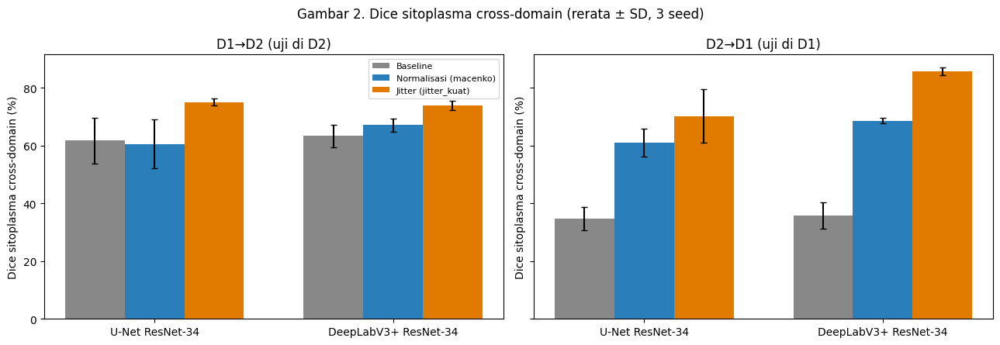

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {'baseline': '#888888', BEST_NORM: '#2a7fba', BEST_JIT: '#e07b00'}
for ax, (src, tgt) in zip(axes, DIRS_PAIR):
    w = 0.25
    for j, c in enumerate(MAIN_CONDS):
        means, sds = [], []
        for arch in ARCHS:
            d = MAIN[(MAIN.source == src) & (MAIN.arch == arch) & (MAIN.cond == c)].cross_dice_sito * 100
            means.append(d.mean()); sds.append(d.std(ddof=1) if len(d) > 1 else 0)
        ax.bar(np.arange(len(ARCHS)) + (j - 1) * w, means, w, yerr=sds, capsize=3, label=COND_NAME[c], color=colors[c])
    ax.set_xticks(range(len(ARCHS))); ax.set_xticklabels(list(ARCHS.values()))
    ax.set_title(f'{src}→{tgt} (uji di {tgt})'); ax.set_ylabel('Dice sitoplasma cross-domain (%)')
axes[0].legend(fontsize=8)
plt.suptitle('Gambar 2. Dice sitoplasma cross-domain (rerata ± SD, 3 seed)')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'gambar2_dice_cross.png', dpi=150); plt.show()

### Sel 28: Tabel 5 laporan (menurut ukuran sel)
Citra uji target dibagi tiga kelompok berdasarkan **luas sitoplasma masker asli** (sepertiga terkecil, tengah, terbesar). Lalu dihitung Dice sitoplasma cross-domain per kelompok untuk baseline, normalisasi, dan jitter (seed 42). Ubah `T5_ARCH` dan `T5_DIR` bila ingin kombinasi lain.

In [ ]:
T5_ARCH, T5_DIR = 'unet', ('D1', 'D2')
src, tgt = T5_DIR
ref = per_image(run_id_of(T5_ARCH, src, tgt, 'baseline', 42), 'cross')[['file', 'area_sito_gt']]
ref['ukuran'] = pd.qcut(ref.area_sito_gt, 3, labels=['Kecil', 'Sedang', 'Besar'], duplicates='drop')
rows = {}
for c in MAIN_CONDS:
    d = per_image(run_id_of(T5_ARCH, src, tgt, c, 42), 'cross').merge(ref[['file', 'ukuran']], on='file')
    g = d.groupby('ukuran', observed=True).dice_sito.mean() * 100
    rows[COND_NAME[c]] = g.round(2)
TABEL5 = pd.DataFrame(rows).T
TABEL5.columns = [f'{c} (n={int((ref.ukuran == c).sum())})' for c in TABEL5.columns]
print(f'Arah {src}→{tgt}, model {ARCHS[T5_ARCH]}, seed 42')
display(TABEL5); save_table(TABEL5, 'tabel5_ukuran_sel')

Arah D1→D2, model U-Net ResNet-34, seed 42


,Kecil (n=7),Sedang (n=6),Besar (n=7)
Baseline,57.85,53.69,51.26
Normalisasi (macenko),63.45,62.79,78.45
Jitter (jitter_kuat),77.42,68.40,74.41


---
## G. Uji ketahanan terhadap pergeseran warna buatan

### Sel 29: Hitung Dice pada citra uji sumber yang digeser warnanya
Untuk **semua model uji utama** (hanya inferensi, tanpa latih ulang):
- citra **uji domain sumber** diberi pergeseran warna buatan: geser **hue**, turunkan **saturasi**, turunkan **kecerahan** pada tiga tingkat (ringan, sedang, berat; besar angkanya ada di `SHIFT_LEVELS`, Sel 3);
- hue digeser ke dua arah (+ dan −) lalu hasilnya dirata-rata;
- untuk model **normalisasi**, citra yang sudah bergeser **dinormalisasi dulu** (referensi dari set latih sumber) sebelum masuk model, sesuai M1;
- level `tanpa` = tanpa pergeseran (titik awal kurva).

Hasil disimpan di `tables/robustness.csv`.

In [ ]:
import torchvision.transforms.functional as TF

def shift_imgs(imgs, hue, sat, bri):
    x = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255
    x = TF.adjust_hue(x, hue); x = TF.adjust_saturation(x, sat); x = TF.adjust_brightness(x, bri)
    return (x.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).numpy()

def mean_dice(pred, gt):
    ds = np.array([[dice_iou(pred[k] == c, gt[k] == c)[0] for c in (1, 2)] for k in range(len(pred))])
    return ds[:, 0].mean(), ds[:, 1].mean()     # sito, nuk

ROB_CSV = DIRS['tables'] / 'robustness.csv'
rob = pd.read_csv(ROB_CSV) if ROB_CSV.exists() else pd.DataFrame(columns=['run_id', 'level', 'dice_sito', 'dice_nuk'])
done = set(zip(rob.run_id, rob.level))
new_rows = []
S = load_summaries()
for r in S[S.cond.isin(MAIN_CONDS)].to_dict('records'):
    rid, src = r['run_id'], r['source']
    todo = [lv for lv in ['tanpa'] + list(SHIFT_LEVELS) if (rid, lv) not in done]
    if not todo: continue
    model, _ = load_run_model(rid)
    idx = SPLIT[src]['test']; raw = DATA[src]['img'][idx]; gt = DATA[src]['mask'][idx]
    nz = get_normalizer(src, r['cond']) if r['cond'] in ('reinhard', 'macenko') else None
    for lv in todo:
        variants = [raw] if lv == 'tanpa' else [shift_imgs(raw, sg * SHIFT_LEVELS[lv][0], SHIFT_LEVELS[lv][1], SHIFT_LEVELS[lv][2]) for sg in (+1, -1)]
        ds = []
        for v in variants:
            if nz is not None:
                v = np.stack([nz(a)[0] for a in v])
            ds.append(mean_dice(predict_u8(model, v), gt))
        new_rows.append(dict(run_id=rid, level=lv, dice_sito=np.mean([d[0] for d in ds]), dice_nuk=np.mean([d[1] for d in ds])))
    del model
if new_rows:
    rob = pd.concat([rob, pd.DataFrame(new_rows)], ignore_index=True)
    rob.to_csv(ROB_CSV, index=False)
print('Baris uji ketahanan:', len(rob))

Baris uji ketahanan: 144


### Sel 30: Tabel 6 dan Gambar 3
**Tabel 6:** Dice sitoplasma (%) pada citra uji sumber dengan pergeseran warna buatan, rerata ± SD antar seed (ubah `T6_ARCH` dan `T6_DIR` untuk model/arah lain). Kolom terakhir **Penurunan berat** = Dice tanpa pergeseran − Dice berat (dipakai untuk H3).
**Gambar 3:** kurva Dice terhadap tingkat pergeseran.

Model U-Net ResNet-34, arah D1→D2 (uji pada citra D1 yang digeser warnanya)


,Tanpa pergeseran,ringan,sedang,berat,Penurunan berat
Kondisi,,,,,
Baseline,94.98 ± 0.17,93.84 ± 0.08,84.13 ± 2.00,68.20 ± 5.03,26.78 ± 5.20
Normalisasi (macenko),93.72 ± 0.10,93.33 ± 0.20,90.42 ± 1.23,86.87 ± 1.41,6.85 ± 1.50
Jitter (jitter_kuat),94.53 ± 0.11,94.56 ± 0.14,94.16 ± 0.07,92.93 ± 0.12,1.60 ± 0.21


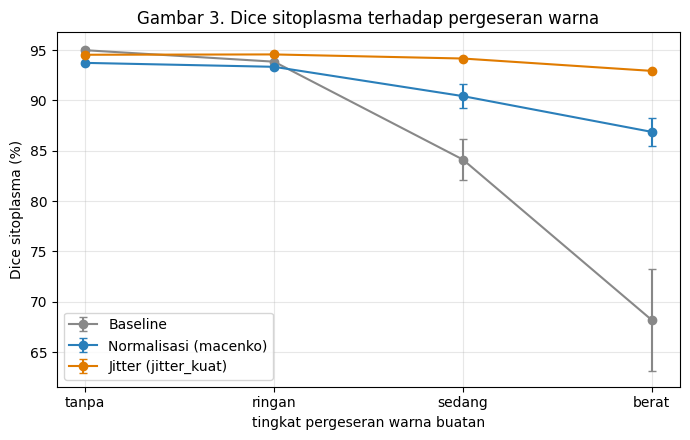

In [ ]:
T6_ARCH, T6_DIR = 'unet', 'D1'
LV = ['tanpa'] + list(SHIFT_LEVELS)
R = rob.merge(S[['run_id', 'arch', 'source', 'cond', 'seed']], on='run_id')
rows, curves = [], {}
for c in MAIN_CONDS:
    d = R[(R.arch == T6_ARCH) & (R.source == T6_DIR) & (R.cond == c)]
    row = {'Kondisi': COND_NAME[c]}
    curves[c] = []
    for lv in LV:
        x = d[d.level == lv].dice_sito * 100
        row[lv if lv != 'tanpa' else 'Tanpa pergeseran'] = f'{x.mean():.2f} ± {x.std(ddof=1):.2f}'
        curves[c].append((x.mean(), x.std(ddof=1)))
    drop = (d[d.level == 'tanpa'].set_index('seed').dice_sito - d[d.level == 'berat'].set_index('seed').dice_sito) * 100
    row['Penurunan berat'] = f'{drop.mean():.2f} ± {drop.std(ddof=1):.2f}'
    rows.append(row)
TABEL6 = pd.DataFrame(rows).set_index('Kondisi')
print(f'Model {ARCHS[T6_ARCH]}, arah {T6_DIR}→{"D2" if T6_DIR == "D1" else "D1"} (uji pada citra {T6_DIR} yang digeser warnanya)')
display(TABEL6); save_table(TABEL6, 'tabel6_ketahanan_warna')

plt.figure(figsize=(7, 4.5))
for c in MAIN_CONDS:
    m = np.array([v[0] for v in curves[c]]); s = np.array([v[1] for v in curves[c]])
    plt.errorbar(range(len(LV)), m, yerr=s, marker='o', capsize=3, label=COND_NAME[c], color=colors[c])
plt.xticks(range(len(LV)), ['tanpa'] + list(SHIFT_LEVELS)); plt.ylabel('Dice sitoplasma (%)'); plt.xlabel('tingkat pergeseran warna buatan')
plt.title('Gambar 3. Dice sitoplasma terhadap pergeseran warna'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'gambar3_ketahanan_warna.png', dpi=150); plt.show()

---
## H. Analisis kesalahan dan interpretabilitas

### Sel 31: Ambil prediksi satu run (alat bantu galeri dan Grad-CAM)
Mengatur **model/arah/seed** yang dianalisis (`G_*`) dan membandingkan **baseline** dengan **kondisi pembanding** (`G_CMP`, default jitter terpilih; ganti ke `BEST_NORM` untuk normalisasi).

In [ ]:
G_ARCH, G_DIR, G_SEED = 'unet', ('D1', 'D2'), 42
G_CMP = BEST_JIT                 # atau BEST_NORM
g_src, g_tgt = G_DIR

def get_run_preds(rid, eval_set='cross'):
    model, s = load_run_model(rid)
    A = get_arrays(s['source'], s['cond'])
    dom = s['target'] if eval_set == 'cross' else s['source']
    idx = SPLIT[dom]['test']
    pred = predict_u8(model, A[dom][idx])
    return dict(model=model, summ=s, idx=idx, dom=dom, raw=DATA[dom]['img'][idx], inp=A[dom][idx], gt=DATA[dom]['mask'][idx],
                pred=pred, df=per_image(rid, eval_set))

RID = {c: run_id_of(G_ARCH, g_src, g_tgt, c, G_SEED) for c in ['baseline', G_CMP]}
PRED = {c: get_run_preds(r) for c, r in RID.items()}
print({c: f"Dice sito cross {PRED[c]['df'].dice_sito.mean() * 100:.2f}" for c in PRED})

{'baseline': 'Dice sito cross 54.29', 'jitter_kuat': 'Dice sito cross 73.66'}


### Sel 32: Galeri ≥ 8 kasus terburuk dan Tabel 9 (kategori kesalahan)
Mengambil **8 segmentasi dengan Dice sitoplasma terendah** untuk baseline dan pembanding, lalu **menebak kategori** dengan aturan sederhana:

| Kategori | Aturan otomatis |
|---|---|
| Nukleus terpecah atau hilang | luas nukleus prediksi < 50% asli, atau komponen nukleus prediksi jauh lebih banyak dari asli |
| Sitoplasma bocor (over) | luas sitoplasma prediksi > 130% asli |
| Sitoplasma kurang (under) | luas sitoplasma prediksi < 70% asli |
| Lainnya / artefak warna | sisanya, **periksa manual** pada gambar |

**Penting:** aturan ini hanya bantuan awal. Lihat galerinya, lalu perbaiki kategori secara manual lewat `OVERRIDE` bila perlu (misalnya `{'baseline': {'012.bmp': 'Artefak warna / tepi buram'}}`) sebelum menyalin Tabel 9 ke laporan.

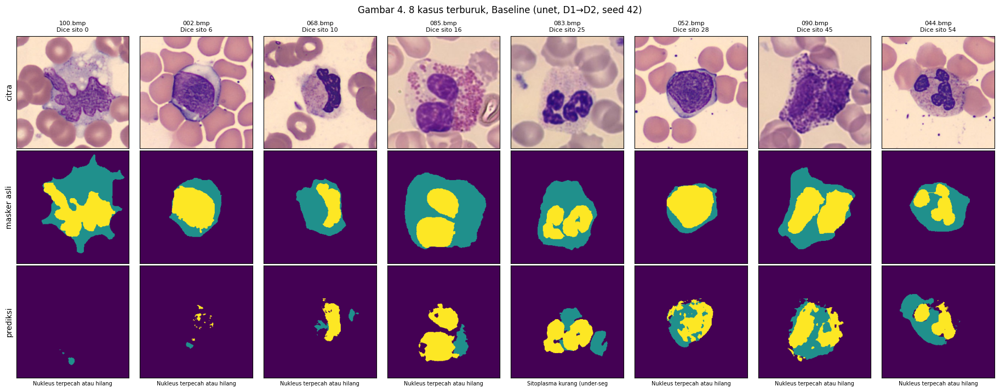

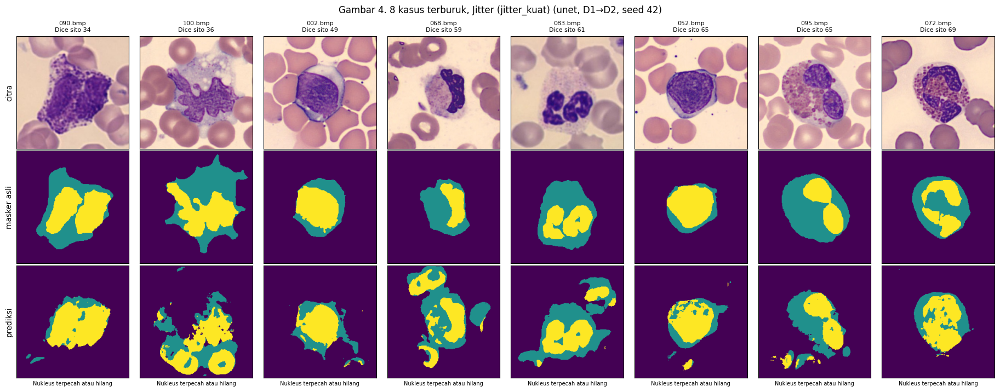

,Baseline (n=8),Jitter (jitter_kuat) (n=8)
kategori,,
Sitoplasma bocor ke latar/RBC (over-segmentation),0,0
Sitoplasma kurang (under-segmentation),1,0
Nukleus terpecah atau hilang,7,8
Lainnya / artefak warna (cek manual),0,0


In [ ]:
OVERRIDE = {}   # contoh: {'baseline': {'012.bmp': 'Artefak warna / tepi buram'}}

def kategori(r, thr=0.30):
    if r.area_nuk_pred < 0.5 * r.area_nuk_gt or r.ncomp_nuk_pred > r.ncomp_nuk_gt + 1 or (r.ncomp_nuk_gt <= 1 and r.ncomp_nuk_pred >= 2):
        return 'Nukleus terpecah atau hilang'
    if r.area_sito_pred > (1 + thr) * r.area_sito_gt: return 'Sitoplasma bocor ke latar/RBC (over-segmentation)'
    if r.area_sito_pred < (1 - thr) * r.area_sito_gt: return 'Sitoplasma kurang (under-segmentation)'
    return 'Lainnya / artefak warna (cek manual)'

K = 8
KAT = ['Sitoplasma bocor ke latar/RBC (over-segmentation)', 'Sitoplasma kurang (under-segmentation)',
       'Nukleus terpecah atau hilang', 'Lainnya / artefak warna (cek manual)']
freq = {}
for c, P in PRED.items():
    df = P['df'].copy()
    df['kategori'] = [OVERRIDE.get(c, {}).get(r.file) or kategori(r) for r in df.itertuples()]
    worst = df.nsmallest(K, 'dice_sito')
    freq[COND_NAME[c]] = worst.kategori.value_counts()
    fig, ax = plt.subplots(3, K, figsize=(2.3 * K, 7.2))
    for j, (_, r) in enumerate(worst.iterrows()):
        i = int(df.index[df.file == r.file][0])
        ax[0, j].imshow(P['raw'][i]); ax[1, j].imshow(P['gt'][i], vmin=0, vmax=2, cmap='viridis'); ax[2, j].imshow(P['pred'][i], vmin=0, vmax=2, cmap='viridis')
        ax[0, j].set_title(f"{r.file}\nDice sito {r.dice_sito * 100:.0f}", fontsize=8)
        ax[2, j].set_xlabel(r.kategori[:28], fontsize=7)
        for a in ax[:, j]: a.set_xticks([]); a.set_yticks([])
    ax[0, 0].set_ylabel('citra'); ax[1, 0].set_ylabel('masker asli'); ax[2, 0].set_ylabel('prediksi')
    plt.suptitle(f'Gambar 4. {K} kasus terburuk, {COND_NAME[c]} ({G_ARCH}, {g_src}→{g_tgt}, seed {G_SEED})')
    plt.tight_layout(); plt.savefig(DIRS['figures'] / f'gambar4_galeri_{c}.png', dpi=130); plt.show()

TABEL9 = pd.DataFrame(freq).reindex(KAT).fillna(0).astype(int)
TABEL9.columns = [f'{c} (n={K})' for c in TABEL9.columns]
display(TABEL9); save_table(TABEL9, 'tabel9_kategori_kesalahan')

### Sel 33: Grad-CAM (Gambar 5 laporan)
Grad-CAM menunjukkan **wilayah citra yang paling memengaruhi keluaran** untuk kelas tertentu. Dihitung pada lapisan terakhir encoder (`encoder.layer4[-1]`, tulis nama ini di Bagian 4.6 laporan) untuk kelas **nukleus** dan **sitoplasma**, pada **4 kasus benar** (Dice sito tertinggi) dan **4 kasus salah** (terendah). Ini diulang untuk baseline dan pembanding.

Tafsirkan sebagai **dugaan**, bukan bukti: Grad-CAM hanya menunjukkan wilayah berpengaruh. Merah/kuning = pengaruh besar.

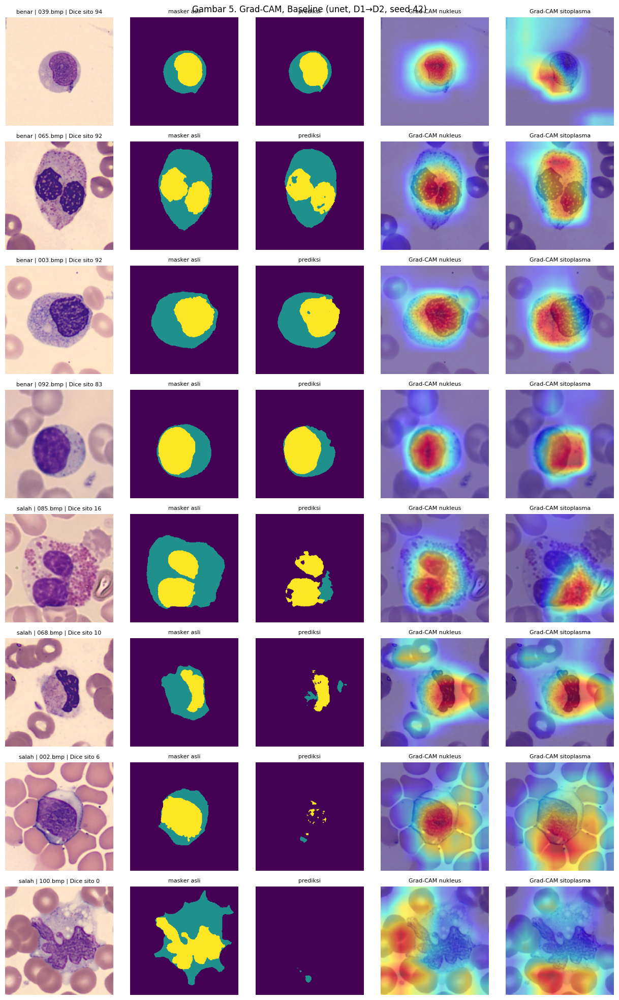

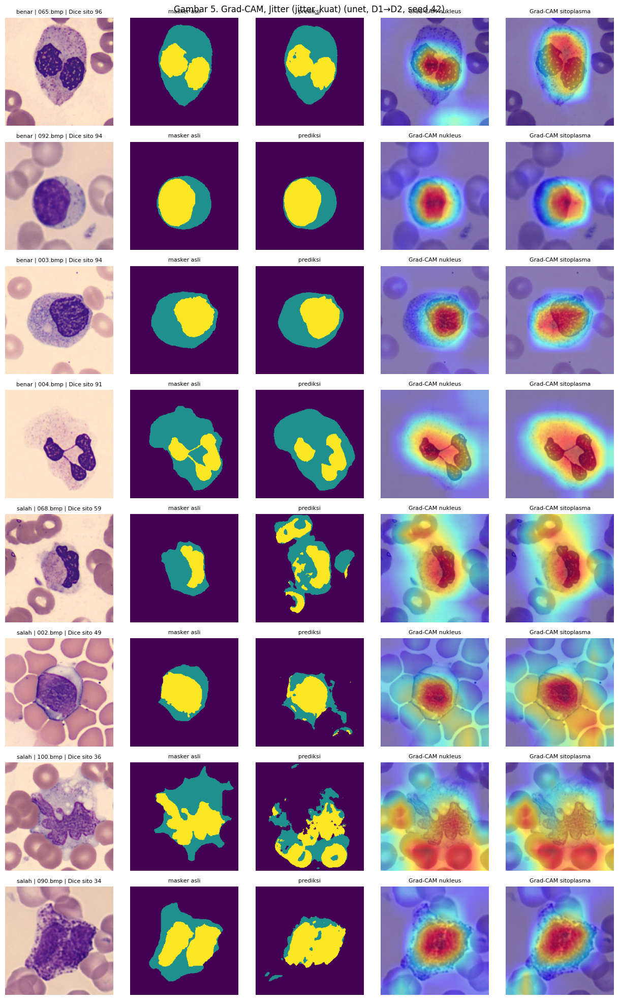

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def cam_for(model, x, cls, mask):
    target_layers = [model.encoder.layer4[-1]]
    if mask.sum() == 0:
        return np.zeros(x.shape[-2:], dtype=np.float32)
    with GradCAM(model=model, target_layers=target_layers) as cam:
        return cam(input_tensor=x, targets=[SemanticSegmentationTarget(cls, mask.astype(np.float32))])[0]

def gradcam_figure(c, n_each=4):
    P = PRED[c]; df = P['df']
    order = df.sort_values('dice_sito', ascending=False)
    cases = [(i, 'benar') for i in order.index[:n_each]] + [(i, 'salah') for i in order.index[-n_each:]]
    model = P['model'].float().eval()
    fig, ax = plt.subplots(len(cases), 5, figsize=(12.5, 2.5 * len(cases)))
    for r, (i, tag) in enumerate(cases):
        x = imagenet_scale(to_gpu_u8(P['inp'][i:i + 1]).float() / 255).requires_grad_(True)
        pred_i = P['pred'][i]
        base_img = P['inp'][i].astype(np.float32) / 255
        ax[r, 0].imshow(P['raw'][i]); ax[r, 0].set_title(f"{tag} | {df.file[i]} | Dice sito {df.dice_sito[i] * 100:.0f}", fontsize=8)
        ax[r, 1].imshow(P['gt'][i], vmin=0, vmax=2, cmap='viridis'); ax[r, 1].set_title('masker asli', fontsize=8)
        ax[r, 2].imshow(pred_i, vmin=0, vmax=2, cmap='viridis'); ax[r, 2].set_title('prediksi', fontsize=8)
        for k, (cls, nm) in enumerate([(2, 'nukleus'), (1, 'sitoplasma')]):
            m = (pred_i == cls)
            if m.sum() == 0: m = (P['gt'][i] == cls)          # bila prediksi kosong, pakai masker asli sebagai sasaran
            g = cam_for(model, x, cls, m)
            ax[r, 3 + k].imshow(show_cam_on_image(base_img, g, use_rgb=True)); ax[r, 3 + k].set_title(f'Grad-CAM {nm}', fontsize=8)
        for a in ax[r]: a.axis('off')
    plt.suptitle(f'Gambar 5. Grad-CAM, {COND_NAME[c]} ({G_ARCH}, {g_src}→{g_tgt}, seed {G_SEED})')
    plt.tight_layout(); plt.savefig(DIRS['figures'] / f'gambar5_gradcam_{c}.png', dpi=120); plt.show()

for c in PRED:
    gradcam_figure(c)

---
## I. Efisiensi, hipotesis, dan ringkasan

### Sel 34: Efisiensi (Tabel 7 laporan)
- **Parameter** (juta) dan **latensi batch 1** (ms/citra, ±SD, rerata ≥ 50 citra setelah warm-up, float32, satu GPU yang sama) untuk kedua arsitektur.
- **Waktu pra-pemrosesan normalisasi** per citra (Reinhard dan Macenko). Jitter tidak menambah waktu saat inferensi.
- **Total jam GPU** pelatihan seluruh run (dari log). Waktu evaluasi dan Grad-CAM tidak termasuk; tambahkan perkiraan bila perlu.

In [ ]:
rows = []
for arch, nm in ARCHS.items():
    m = build_model(arch, pretrained=False).to(device)
    lat, sd = measure_latency(m, n=60, warmup=10)
    rows.append({'Model': nm, 'Parameter (juta)': round(n_params_million(m), 2), 'Latensi (ms/citra)': f'{lat:.1f} ± {sd:.1f}', 'Citra/detik': round(1000 / lat, 1)})
    del m
TABEL7 = pd.DataFrame(rows).set_index('Model')
print(f'GPU: {GPU_NAME} | batch 1 | float32 | 60 citra setelah 10 warm-up')
display(TABEL7); save_table(TABEL7, 'tabel7_efisiensi')

sample = DATA['D2']['img'][SPLIT['D2']['test']][:50]
for mth in ['reinhard', 'macenko']:
    nz = get_normalizer('D1', mth)
    t0 = time.perf_counter()
    for a in sample: nz(a)
    print(f'Waktu {mth}: {(time.perf_counter() - t0) / len(sample) * 1000:.1f} ms/citra (256×256, CPU)')

S = load_summaries()
tot = S.train_time_sec.sum() / 3600
print(f'\nTotal waktu latih tercatat: {tot:.2f} jam GPU ({len(S)} run) -> isi di Tabel 2 laporan')

GPU: Tesla T4 | batch 1 | float32 | 60 citra setelah 10 warm-up


,Parameter (juta),Latensi (ms/citra),Citra/detik
Model,,,
U-Net ResNet-34,24.44,7.8 ± 0.9,128.6
DeepLabV3+ ResNet-34,22.44,7.5 ± 0.8,134.0


Waktu reinhard: 24.7 ms/citra (256×256, CPU)
Waktu macenko: 32.5 ms/citra (256×256, CPU)

Total waktu latih tercatat: 1.02 jam GPU (42 run) -> isi di Tabel 2 laporan


### Sel 35: Uji hipotesis (Tabel 8 laporan)
Menghitung H1–H3 **otomatis** dengan kriteria yang sama seperti proposal. Semua angka dalam **poin Dice (%)**.

- **H1:** selisih Dice sito. D1→D2 (in − cross): `normalisasi − jitter ≥ 2 poin` (rerata 3 seed, U-Net). Dihitung pada konfigurasi **terpilih** (3 seed). Sebagai pembanding juga dihitung versi tepat sesuai teks hipotesis (Macenko vs jitter kuat) dari ablasi seed 42.
- **H2:** |Dice sito. cross Reinhard − Macenko| < 1 poin (ablasi seed 42, kedua arah).
- **H3:** pada pergeseran **berat**, penurunan Dice sito. model jitter lebih kecil daripada baseline dan model normalisasi (diperiksa pada tiap kombinasi model × arah).


In [ ]:
S = load_summaries()
MAIN = pd.DataFrame([{**r, **run_metrics(r['run_id'])} for r in S.to_dict('records')])
def gap(cond, arch='unet', src='D1', seed=None):
    d = MAIN[(MAIN.arch == arch) & (MAIN.source == src) & (MAIN.cond == cond)]
    if seed is not None: d = d[d.seed == seed]
    return d.gap_dice_sito.mean() * 100

h1_main = gap(BEST_NORM) - gap(BEST_JIT)
h1_exact = gap('macenko', seed=42) - gap('jitter_kuat', seed=42)
h2 = {f'{s}→{t}': abs(sv('reinhard', s, t, 'cross_dice_sito') - sv('macenko', s, t, 'cross_dice_sito')) * 100 for s, t in DIRS_PAIR}

R = rob.merge(S[['run_id', 'arch', 'source', 'cond', 'seed']], on='run_id')
h3_rows = []
for arch in ARCHS:
    for src, tgt in DIRS_PAIR:
        d = R[(R.arch == arch) & (R.source == src)]
        def drop(c):
            x = d[d.cond == c]
            a = x[x.level == 'tanpa'].set_index('seed').dice_sito; b = x[x.level == 'berat'].set_index('seed').dice_sito
            return ((a - b) * 100).mean()
        dj, db, dn = drop(BEST_JIT), drop('baseline'), drop(BEST_NORM)
        h3_rows.append(dict(model=ARCHS[arch], arah=f'{src}→{tgt}', turun_jitter=dj, turun_baseline=db, turun_norm=dn, hold=(dj < db) and (dj < dn)))
H3 = pd.DataFrame(h3_rows).round(2)
display(H3)
h3_ok = bool(H3.hold.all())

yn = lambda b: 'Terbukti' if b else 'Tidak terbukti'
TABEL8 = pd.DataFrame([
    ['H1', 'Selisih Dice sito. D1→D2: normalisasi − jitter ≥ 2 poin (rerata 3 seed, U-Net)',
     f'{BEST_NORM} − {BEST_JIT}: {h1_main:+.2f} poin (versi Macenko − jitter kuat, seed 42: {h1_exact:+.2f})', yn(h1_main >= 2)],
    ['H2', 'Selisih Dice Reinhard vs Macenko < 1 poin (cross, seed 42)',
     ' | '.join(f'{k}: {v:.2f} poin' for k, v in h2.items()), yn(all(v < 1 for v in h2.values()))],
    ['H3', 'Penurunan Dice sito. tingkat berat: jitter < baseline dan < normalisasi',
     f'{int(H3.hold.sum())} dari {len(H3)} kombinasi model×arah memenuhi (tabel di atas)', yn(h3_ok)],
], columns=['Kode', 'Kriteria', 'Hasil', 'Kesimpulan'])
pd.set_option('display.max_colwidth', 200)
display(TABEL8); save_table(TABEL8, 'tabel8_hipotesis', index=False)

,model,arah,turun_jitter,turun_baseline,turun_norm,hold
0,U-Net ResNet-34,D1→D2,1.60,26.78,6.85,True
1,U-Net ResNet-34,D2→D1,3.62,63.60,23.40,True
2,DeepLabV3+ ResNet-34,D1→D2,1.91,27.14,6.51,True
3,DeepLabV3+ ResNet-34,D2→D1,2.22,71.31,23.26,True


,Kode,Kriteria,Hasil,Kesimpulan
0,H1,"Selisih Dice sito. D1→D2: normalisasi − jitter ≥ 2 poin (rerata 3 seed, U-Net)","macenko − jitter_kuat: +13.66 poin (versi Macenko − jitter kuat, seed 42: +4.36)",Terbukti
1,H2,"Selisih Dice Reinhard vs Macenko < 1 poin (cross, seed 42)",D1→D2: 40.60 poin | D2→D1: 0.59 poin,Tidak terbukti
2,H3,Penurunan Dice sito. tingkat berat: jitter < baseline dan < normalisasi,4 dari 4 kombinasi model×arah memenuhi (tabel di atas),Terbukti


### Sel 36 (opsional): Uji eksternal zero-shot pada LISC
Hanya dijalankan bila Anda **berhasil mendapatkan LISC** dengan masker nukleus–sitoplasma. Siapkan folder berisi citra dan masker 3 kelas (latar 0, sitoplasma 128, nukleus 255), lalu isi `LISC_IMG_DIR` dan `LISC_MASK_DIR`.

Model yang diuji: model terbaik tiap arsitektur (arah D1→D2, seed 42, kondisi `G_CMP`). Hasil disimpan di `tables/lisc_zero_shot.csv`.

In [ ]:
LISC_IMG_DIR = None    # contoh: '/content/drive/MyDrive/TimTam_T3A/data/LISC/images'
LISC_MASK_DIR = None   # contoh: '/content/drive/MyDrive/TimTam_T3A/data/LISC/masks'

if LISC_IMG_DIR and LISC_MASK_DIR and Path(LISC_IMG_DIR).exists() and Path(LISC_MASK_DIR).exists():
    imgs_, msks_, pairs_ = pair_files(Path(LISC_IMG_DIR), Path(LISC_MASK_DIR))
    print(f'LISC: {len(pairs_)} pasangan')
    X, Y, N = [], [], []
    for ip, mp in pairs_:
        X.append(np.array(Image.open(ip).convert('RGB').resize((IMG, IMG), Image.BILINEAR)))
        q, _ = quantize(np.array(Image.open(mp).convert('L')))
        Y.append(np.array(Image.fromarray(q).resize((IMG, IMG), Image.NEAREST))); N.append(ip.name)
    X, Y = np.stack(X), np.stack(Y)
    rows = []
    for arch in ARCHS:
        for c in ['baseline', G_CMP]:
            rid = run_id_of(arch, 'D1', 'D2', c, 42)
            if not (DIRS['ckpt'] / f'{rid}.pt').exists(): continue
            model, s = load_run_model(rid)
            Xin = np.stack([get_normalizer('D1', c)(a)[0] for a in X]) if c in ('reinhard', 'macenko') else X
            df = metrics_df(predict_u8(model, Xin), Y, N)
            rows.append(dict(run_id=rid, dice_nuk=df.dice_nuk.mean() * 100, dice_sito=df.dice_sito.mean() * 100, miou=df.miou.mean() * 100, hd95_sito=df.hd95_sito.mean()))
    LISC = pd.DataFrame(rows).round(2); display(LISC); save_table(LISC, 'lisc_zero_shot', index=False)
else:
    print('Folder LISC tidak diatur/tidak ditemukan -> uji eksternal dilewati (opsional).')

Folder LISC tidak diatur/tidak ditemukan -> uji eksternal dilewati (opsional).


### Sel 37: Ringkasan angka untuk Abstrak, Kesimpulan, dan Tabel 2


In [ ]:
S = load_summaries()
print('=== TABEL 2: konfigurasi pelatihan (isi bagian [..]) ===')
print(f'Epoch maksimum {MAX_EPOCHS}, kesabaran early stopping {PATIENCE} epoch')
print(f"GPU: {VERSIONS['gpu']} | PyTorch {VERSIONS['torch']} | segmentation_models_pytorch {VERSIONS['smp']}")
print(f'Total jam GPU latih: {S.train_time_sec.sum() / 3600:.2f} | jumlah run: {len(S)}')
print('Jitter: lemah/sedang/kuat =', {k: v for k, v in JITTER.items()})
print('Pergeseran warna buatan (hue, saturasi, kecerahan):', SHIFT_LEVELS)
fails = pd.concat([pd.read_csv(p) for p in DIRS['logs'].glob('normalisasi_gagal_macenko_ref*.csv')], ignore_index=True) if list(DIRS['logs'].glob('normalisasi_gagal_macenko_ref*.csv')) else pd.DataFrame()
print('Citra gagal Macenko (fallback Reinhard):', len(fails))
if (DIRS['logs'] / 'run_gagal.csv').exists():
    print('Run gagal:', sum(1 for _ in open(DIRS['logs'] / 'run_gagal.csv')))

print('\n=== KONFIGURASI TERPILIH (berdasar validasi domain target) ===')
print('Normalisasi:', BEST_NORM, '| Jitter:', BEST_JIT)

print('\n=== SELISIH DICE SITO. (in - cross), rerata 3 seed, poin ===')
for arch in ARCHS:
    for src, tgt in DIRS_PAIR:
        vals = {c: gap(c, arch, src) for c in MAIN_CONDS}
        best = min(vals, key=vals.get)
        print(f'{ARCHS[arch]:22s} {src}→{tgt}:', {k: round(v, 2) for k, v in vals.items()}, '-> terkecil:', best)

print('\n=== STATUS HIPOTESIS ===')
display(TABEL8[['Kode', 'Hasil', 'Kesimpulan']])

=== TABEL 2: konfigurasi pelatihan (isi bagian [..]) ===
Epoch maksimum 100, kesabaran early stopping 15 epoch
GPU: Tesla T4 | PyTorch 2.14.1+cu130 | segmentation_models_pytorch 0.6.0
Total jam GPU latih: 1.02 | jumlah run: 42
Jitter: lemah/sedang/kuat = {'jitter_lemah': {'b': 0.1, 'c': 0.1, 's': 0.1, 'h': 0.02}, 'jitter_sedang': {'b': 0.3, 'c': 0.3, 's': 0.3, 'h': 0.05}, 'jitter_kuat': {'b': 0.5, 'c': 0.5, 's': 0.5, 'h': 0.1}}
Pergeseran warna buatan (hue, saturasi, kecerahan): {'ringan': (0.03, 0.8, 0.85), 'sedang': (0.08, 0.6, 0.7), 'berat': (0.15, 0.4, 0.55)}
Citra gagal Macenko (fallback Reinhard): 0

=== KONFIGURASI TERPILIH (berdasar validasi domain target) ===
Normalisasi: macenko | Jitter: jitter_kuat

=== SELISIH DICE SITO. (in - cross), rerata 3 seed, poin ===
U-Net ResNet-34        D1→D2: {'baseline': np.float64(33.23), 'macenko': np.float64(33.18), 'jitter_kuat': np.float64(19.52)} -> terkecil: jitter_kuat
U-Net ResNet-34        D2→D1: {'baseline': np.float64(59.26), 'mace

,Kode,Hasil,Kesimpulan
0,H1,"macenko − jitter_kuat: +13.66 poin (versi Macenko − jitter kuat, seed 42: +4.36)",Terbukti
1,H2,D1→D2: 40.60 poin | D2→D1: 0.59 poin,Tidak terbukti
2,H3,4 dari 4 kombinasi model×arah memenuhi (tabel di atas),Terbukti


### Sel 38: Kemas hasil untuk repositori dan lampiran


In [ ]:
try:
    with pd.ExcelWriter(DIRS['tables'] / 'semua_tabel.xlsx') as xw:
        for p in sorted(DIRS['tables'].glob('*.csv')):
            pd.read_csv(p).to_excel(xw, sheet_name=p.stem[:31], index=False)
    print('Tersimpan:', DIRS['tables'] / 'semua_tabel.xlsx')
except Exception as e:
    print('Gagal membuat Excel (tidak masalah, CSV tetap ada):', e)

print('\nIsi folder proyek:')
for k, p in DIRS.items():
    n = sum(1 for _ in p.rglob('*') if _.is_file())
    print(f'  {k:8s} {n:4d} berkas  -> {p}')
print("""
Checklist repositori GitHub:
  [x] notebook ini (.ipynb)
  [x] splits/split_seed42.csv
  [x] logs/ (audit, duplikat, normalisasi gagal, run gagal, lingkungan, konfigurasi terpilih)
  [x] tables/ dan figures/ (angka dan gambar laporan)
  [x] results/*/summary.json dan history.csv (log tiap run, termasuk yang gagal)
  [ ] README.md: langkah reproduksi (urutan sel, versi pustaka dari logs/lingkungan.json)
  [ ] JANGAN unggah: dataset Zheng, folder ckpt/
""")

Tersimpan: /content/drive/MyDrive/TimTam_T3A/tables/semua_tabel.xlsx

Isi folder proyek:
  data        1 berkas  -> /content/drive/MyDrive/TimTam_T3A/data
  splits      1 berkas  -> /content/drive/MyDrive/TimTam_T3A/splits
  logs       11 berkas  -> /content/drive/MyDrive/TimTam_T3A/logs
  ckpt       42 berkas  -> /content/drive/MyDrive/TimTam_T3A/ckpt
  figures    11 berkas  -> /content/drive/MyDrive/TimTam_T3A/figures
  tables     12 berkas  -> /content/drive/MyDrive/TimTam_T3A/tables
  results   126 berkas  -> /content/drive/MyDrive/TimTam_T3A/results

Checklist repositori GitHub:
  [x] notebook ini (.ipynb)
  [x] splits/split_seed42.csv
  [x] logs/ (audit, duplikat, normalisasi gagal, run gagal, lingkungan, konfigurasi terpilih)
  [x] tables/ dan figures/ (angka dan gambar laporan)
  [x] results/*/summary.json dan history.csv (log tiap run, termasuk yang gagal)
  [ ] README.md: langkah reproduksi (urutan sel, versi pustaka dari logs/lingkungan.json)
  [ ] JANGAN unggah: dataset Zhe